In [2]:
import pickle
import uproot
import os
import math
import pandas as pd
import matplotlib.pyplot as plt
import xgboost as xgb
import numpy as np
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_curve

In [3]:
basePath = "/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms/"
mcFile = uproot.open(basePath+"ZmmSim_BaseEventFiltered.root")
#mcFile = uproot.open(basePath+"ZmmSim_EndcapMuFilter.root")
offPeakData = uproot.open(basePath+"offPeakCR_2018Data.root")
sameSignData = uproot.open(basePath+"sameSignCR_2018Data.root")
sigFile = uproot.open(basePath+"ZmmDBrem_map0p2_fixBiasing.root")
partialData = uproot.open(basePath+"partialRegionData.root")
tagAlignedData = uproot.open(basePath+"highHcal_data_tagAligned.root")
mcFile_highHCAL = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms/highHcal_mc.root")    
dataFile_highHCAL = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms/highHcal_data.root")
sameSignFile_highHCAL = uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/histograms/sameSignCR_highHcal_2018Data.root")

In [4]:
BDTs = []
for dataSet in range(5):
    BDTs.append([pickle.load(open("/home/krohn045/BDT_output/partialRegion"+str(dataSet)+"_2023-08-08.pickle.dat", "rb")),
                 pickle.load(open("/home/krohn045/BDT_output/trainingDataset"+str(dataSet)+"_2023-08-08.pkl", "rb"))])

In [5]:
def getHeDepthWeight(bins,sfhist,heEnergy):
    weights = []
    newE = heEnergy.copy()
    for energyIndex, energy in enumerate(heEnergy):
        lastvalue = None
        foundbin = False
        if energy<0:
            weights.append(1)
            continue;
        for idx, value in enumerate(bins):
            if(value>energy):
                if idx==1:
                    newE[energyIndex]=0
                weights.append(lastvalue)
                foundbin = True
                break
            lastvalue = sfhist[idx]
        if not foundbin:
            weights.append(lastvalue)
    return [np.array(weights), newE]

In [6]:
def getOldHeDepthWeight(sfhist,heEnergy):
    weights = []
    newE = heEnergy.copy()
    for energyIndex, energy in enumerate(heEnergy):
        lastvalue = 1
        foundbin = False
        for idx, value in enumerate(sfhist.values()):
            if(sfhist.axis().edges()[idx]>energy):
                if idx==1:
                    heEnergy[energyIndex]=0
                weights.append(lastvalue)
                foundbin = True
                break
            if(value>0):
                lastvalue = value
        if not foundbin:
            weights.append(lastvalue)
    return [np.array(weights), newE]

In [7]:
bdtfeatures = ["pt",
               "eta",
               "phi",
               "staDR",
               "staPhi",
               "staE",
               "staChi",
               "cscDR",
               "HEDepth_0",
               "HEDepth_1",
               "HEDepth_2",
               "HEDepth_3",
               "HEDepth_4",
               "HEDepth_5",
               "HEDepth_6",
               "probeCharge",
               "standaloneDEoverE",
               "cscDRbyStation_0",
               "cscDRbyStation_1",
               "cscDRbyStation_2",
               "cscDRbyStation_3"]
              
nonBDTfeats = ["cscDEtabyStation_0",
               "cscDEtabyStation_1",
               "cscDEtabyStation_2",
               "cscDEtabyStation_3",
               "cscDPhibyStation_0",
               "cscDPhibyStation_1",
               "cscDPhibyStation_2",
               "cscDPhibyStation_3",
               "cscDZbyStation_0",
               "cscDZbyStation_1",
               "cscDZbyStation_2",
               "cscDZbyStation_3",
               "EventWeight",
               "cellEdgeDeta",
               "cellEdgeDphi",
               "found_HEDepth_0",
               "found_HEDepth_1",
               "found_HEDepth_2",
               "found_HEDepth_3",
               "found_HEDepth_4",
               "found_HEDepth_5",
               "found_HEDepth_6"]
secCSCDrs = ["seccscDRbyStation_0",
             "seccscDRbyStation_1",
             "seccscDRbyStation_2",
             "seccscDRbyStation_3",
             "seccscDPhibyStation_0",
             "seccscDPhibyStation_1",
             "seccscDPhibyStation_2",
             "seccscDPhibyStation_3"]
nCloseHits = ["nCloseHitsStation_0",
              "nCloseHitsStation_1",
              "nCloseHitsStation_2",
              "nCloseHitsStation_3"]
puWeights = ["PUupWeight",
             "PUdownWeight"]
allfeatures = bdtfeatures+nonBDTfeats

offPeak_data=offPeakData["demo"]["partialDisappear"]["sigVariables"]
sameSign_data=sameSignData["demo"]["partialDisappear"]["sigVariables"]
partial_data=partialData["demo"]["partialDisappear"]["sigVariables"]
tagAligned_data=tagAlignedData["demo"]["partialDisappear"]["sigVariables"]
mc = mcFile["demo"]["partialDisappear"]["sigVariables"]
signal = sigFile["demo"]["partialDisappear"]["sigVariables"]
highHcalData = dataFile_highHCAL["demo"]["partialDisappear"]["sigVariables"]
highHcalMC = mcFile_highHCAL["demo"]["partialDisappear"]["sigVariables"]
sameSignHighHcal = sameSignFile_highHCAL["demo"]["partialDisappear"]["sigVariables"]
offPeak_arr = offPeak_data.arrays(allfeatures+["invMass"]+nCloseHits+secCSCDrs,library="pd")
sameSign_arr = sameSign_data.arrays(allfeatures, library="pd")
highHcalData_arr = highHcalData.arrays(allfeatures, library="pd")
highHcalMC_arr = highHcalMC.arrays(allfeatures, library="pd")
sameSignHighHcal_arr = sameSignHighHcal.arrays(allfeatures, library="pd")
mc_arr = mc.arrays(allfeatures+secCSCDrs+puWeights, library="pd")
sig_arr = signal.arrays(allfeatures, library="pd")
partial_arr = partial_data.arrays(allfeatures+secCSCDrs, library="pd")
tagAligned_arr = tagAligned_data.arrays(allfeatures, library="pd")

In [8]:
print(highHcalData_arr.shape[0])
print(highHcalMC_arr.shape[0])

96456
24239


In [9]:
def edgeCond(arr):
    etaEdgeCond = ((arr["eta"]>0)&(arr["cellEdgeDeta"]<0.002)&(arr["cellEdgeDeta"]>-0.016))|((arr["eta"]<0)&(arr["cellEdgeDeta"]>-0.002)&(arr["cellEdgeDeta"]<0.016))
    phiEdgeCond = ((abs(arr["phi"])>1.5)&(arr["cellEdgeDphi"]<0.001)&(arr["cellEdgeDphi"]>-0.004))|((abs(arr["phi"])<1.5)&(arr["cellEdgeDphi"]<0.004)&(arr["cellEdgeDphi"]>-0.001))
    return etaEdgeCond|phiEdgeCond

In [10]:
def setZeroes(dataframe):
    copyframe = dataframe.copy()
    for depth in range(0,7):
        colcopy = [-1] * dataframe.shape[0]
        for idx, entry in enumerate(dataframe['HEDepth_'+str(depth)]):
            if dataframe['found_HEDepth_'+str(depth)].iloc[idx]>0.5:
                colcopy[idx] = entry
        copyframe['HEDepth_'+str(depth)] = colcopy
    return copyframe

In [11]:
offPeakDataEvents = offPeak_arr[~edgeCond(offPeak_arr)&(offPeak_arr['standaloneDEoverE']<-0.6)].copy()
sameSignDataEvents = sameSign_arr[~edgeCond(sameSign_arr)&(sameSign_arr['standaloneDEoverE']<-0.6)].copy()
mcEvents = mc_arr[~edgeCond(mc_arr)&(mc_arr['standaloneDEoverE']<-0.6)].copy()
sigEvents = sig_arr[~edgeCond(sig_arr)&(sig_arr['standaloneDEoverE']<-0.6)].copy()
partialEvents = partial_arr[~edgeCond(partial_arr)&(partial_arr['standaloneDEoverE']<-0.6)].copy()
tagAlignedEvents = tagAligned_arr[abs(tagAligned_arr['eta'])>1.6]
highHcalDataEvents = highHcalData_arr[~edgeCond(highHcalData_arr)&(highHcalData_arr['standaloneDEoverE']<-0.6)].copy()
highHcalMCEvents = highHcalMC_arr[~edgeCond(highHcalMC_arr)&(highHcalMC_arr['standaloneDEoverE']<-0.6)].copy()
sameSignHighHcalEvents = sameSignHighHcal_arr[~edgeCond(sameSignHighHcal_arr)&(sameSignHighHcal_arr['standaloneDEoverE']<-0.6)].copy()
mcEvents['staPhi']=mcEvents['staPhi']*mcEvents['probeCharge']
offPeakDataEvents['staPhi']=offPeakDataEvents['staPhi']*offPeakDataEvents['probeCharge']
sameSignDataEvents['staPhi']=sameSignDataEvents['staPhi']*sameSignDataEvents['probeCharge']
partialEvents['staPhi']=partialEvents['staPhi']*partialEvents['probeCharge']
sigEvents['staPhi']=sigEvents['staPhi']*sigEvents['probeCharge']
highHcalDataEvents['staPhi']=highHcalDataEvents['staPhi']*highHcalDataEvents['probeCharge']
highHcalMCEvents['staPhi']=highHcalMCEvents['staPhi']*highHcalMCEvents['probeCharge']
sameSignHighHcalEvents['staPhi']=sameSignHighHcalEvents['staPhi']*sameSignHighHcalEvents['probeCharge']
partialEvents = setZeroes(partialEvents)
offPeakDataEvents = setZeroes(offPeakDataEvents)
highHcalDataEvents = setZeroes(highHcalDataEvents)
highHcalMCEvents = setZeroes(highHcalMCEvents)
sameSignHighHcalEvents = setZeroes(sameSignHighHcalEvents)

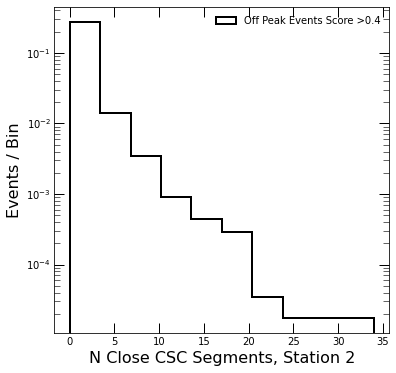

In [100]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [binx/1200-0.02 for binx in range(51)]
#binsx = [binx+50 for binx in range(101)]

highScoreOffHist = offPlot.hist(offPeakDataEvents['nCloseHitsStation_3'],density=True,label='Off Peak Events Score >0.4',histtype='step',bins=10,linewidth=2, color='black')

plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("N Close CSC Segments, Station 2",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [13]:
#with open("HcalSFs.pickle", 'rb') as pickle_file:
#    sfBins, hcalSfHists = pickle.load(pickle_file)

hcalSfHists = []
for depth in range(7):
   hcalSfHists.append(uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/jupyterstuff/hcalSFs.root:hcalSF_depth"+str(depth)))
    
weightedMCInputs = mcEvents.copy()
firstDepth = getOldHeDepthWeight(hcalSfHists[0], weightedMCInputs["HEDepth_0"])
reweight = firstDepth[0]
weightedMCInputs['HEDepth_0']=firstDepth[1]
for depth in range(1,7):
    thisDepth = getOldHeDepthWeight(hcalSfHists[depth],weightedMCInputs['HEDepth_'+str(depth)])
    reweight = reweight*thisDepth[0]
    weightedMCInputs['HEDepth_'+str(depth)]=thisDepth[1]
weightedMCInputs['HEWeight']=reweight
weightedMCInputs['EventWeight']=weightedMCInputs['EventWeight']*reweight 

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  # Remove the CWD from sys.path while we load stuff.


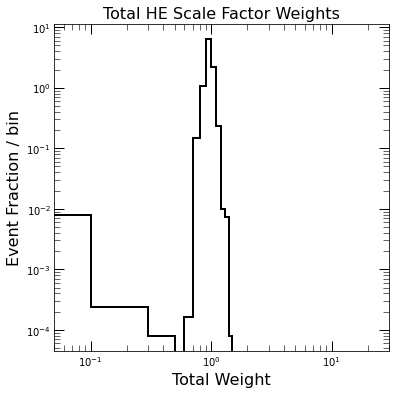

106
124875


In [14]:
weightBins = [x/10. for x in range(200)]

#noWeightHist = plt.hist(tagMC['hitEnergiesDepth3'],alpha=0.5, density=True, bins=100,label='non-reweight')
fig, weightPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
dataHist = weightPlot.hist(weightedMCInputs['EventWeight']/weightedMCInputs['HEWeight'],bins=weightBins,density=True,label='weights',histtype='step',linewidth=2, color='black')
plt.yscale("log")
plt.xscale("log")
plt.title('Total HE Scale Factor Weights',fontsize=16)
plt.xlabel('Total Weight',fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
weightPlot.yaxis.set_ticks_position('both')
weightPlot.xaxis.set_ticks_position('both')
plt.xlim([0.05,30])
plt.savefig("plots/totalHEWeights.pdf")
plt.show()
print(weightedMCInputs[(weightedMCInputs['EventWeight']/weightedMCInputs['HEWeight'])<0.4].shape[0])
print(weightedMCInputs.shape[0])

In [15]:
#print(BDT.get_booster().get_score(importance_type='gain'))
#mc_preds = BDT.predict(weightedMCInputs)
mcBDTInputs = weightedMCInputs.copy()
mcBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
mcBDTInputs.drop("HEWeight",inplace=True,axis=1)
mcBDTInputs.drop(secCSCDrs,inplace=True,axis=1)
mcBDTInputs.drop(puWeights,inplace=True,axis=1)
sigBDTInputs = sigEvents.copy()
sigBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
highHcalDataBDTInputs = highHcalDataEvents.copy()
highHcalDataBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
highHcalMCBDTInputs = highHcalMCEvents.copy()
highHcalMCBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
sameSignHighHcalBDTInputs = sameSignHighHcalEvents.copy()
sameSignHighHcalBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
partialBDTInputs = partialEvents.copy()
partialBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
partialBDTInputs.drop(secCSCDrs,inplace=True,axis=1)
offPeakBDTInputs = offPeakDataEvents.copy()
offPeakBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
offPeakBDTInputs.drop("invMass",inplace=True,axis=1)
offPeakBDTInputs.drop(secCSCDrs,inplace=True,axis=1)
offPeakBDTInputs.drop(nCloseHits,inplace=True,axis=1)
sameSignBDTInputs = sameSignDataEvents.copy()
sameSignBDTInputs.drop(nonBDTfeats,inplace=True,axis=1)


In [16]:
testBDTInputs=[]
adjTestBDTInputs=[]
for kfold in range(5):
    BDTs[kfold][1] = BDTs[kfold][1][BDTs[kfold][1]['label']==0]
    testBDTInputs.append(BDTs[kfold][1].copy())
    testBDTInputs[-1].drop('trainingWeight',inplace=True,axis=1)
    testBDTInputs[-1].drop('label',inplace=True,axis=1)
    adjTestBDTInputs.append(testBDTInputs[-1].copy())
    secondMinDr = [10] * adjTestBDTInputs[-1].shape[0]
    minDr = [10] * adjTestBDTInputs[-1].shape[0]

    for station in range(0,4):
        for idx, entry in enumerate(adjTestBDTInputs[-1]['cscDRbyStation_'+str(station)]):
            if entry>0 and entry<minDr[idx]:
                secondMinDr[idx] = minDr[idx]
                minDr[idx] = entry
            elif entry>0 and entry<secondMinDr[idx]:
                secondMinDr[idx] = entry
    adjTestBDTInputs[-1]['cscDR'] = secondMinDr

In [94]:
def cscCut(dataFrame):
    cutVal = 5.
    cutCond = (dataFrame['cscDPhibyStation_1']*dataFrame['probeCharge']<cutVal)
    return cutCond

mc_preds = BDTs[0][0].predict(mcBDTInputs)
for thisbdt in BDTs:
    mc_preds_this = thisbdt[0].predict(mcBDTInputs)
    for idx, val in enumerate(mc_preds_this):
        if val>mc_preds[idx]:
            mc_preds[idx] = val
sig_preds = BDTs[0][0].predict(sigBDTInputs)
offPeak_preds = BDTs[0][0].predict(offPeakBDTInputs)
partial_preds = BDTs[0][0].predict(partialBDTInputs)
sameSign_preds = BDTs[0][0].predict(sameSignBDTInputs)
highHcalData_preds = BDTs[0][0].predict(highHcalDataBDTInputs)
highHcalMC_preds = BDTs[0][0].predict(highHcalMCBDTInputs)
sameSignHighHcal_preds = BDTs[0][0].predict(sameSignHighHcalBDTInputs)
test_preds = [BDTs[dataSet][0].predict(testBDTInputs[dataSet]) for dataSet in range(5)]
adj_test_preds = [BDTs[dataSet][0].predict(adjTestBDTInputs[dataSet]) for dataSet in range(5)]
for dataSet in range(5):
    BDTs[dataSet][1]['BDTScore'] = test_preds[dataSet]
    BDTs[dataSet][1]['AdjBDTScore'] = adj_test_preds[dataSet]
allBDTs = pd.concat([BDTs[0][1],BDTs[1][1],BDTs[2][1],BDTs[3][1],BDTs[4][1]])
scoredMC = weightedMCInputs.copy()
for idx, entry in enumerate(scoredMC['EventWeight']):
    if entry/scoredMC['HEWeight'].iloc[idx]<0.4:
        scoredMC['EventWeight'].iloc[idx] = scoredMC['HEWeight'].iloc[idx]
scoredMC['BDTScore'] = mc_preds
lowScoreMC = scoredMC.copy()
#lowScoreMC = lowScoreMC[lowScoreMC['BDTScore']<0.7]
scoredHighHcalData = highHcalDataEvents.copy()
scoredHighHcalData['BDTScore'] = highHcalData_preds
scoredHighHcalMC = highHcalMCEvents.copy()
scoredHighHcalMC['BDTScore'] = highHcalMC_preds
scoredSameSignHighHcal = sameSignHighHcalEvents.copy()
scoredSameSignHighHcal['BDTScore'] = sameSignHighHcal_preds
lowScoreMC = lowScoreMC[cscCut(lowScoreMC)]
lowScoreData = partialEvents.copy()
lowScoreData['BDTScore'] = partial_preds
lowScoreData = lowScoreData[lowScoreData['BDTScore']<0.7]
lowScoreData = lowScoreData[cscCut(lowScoreData)]
#lowScoreData = lowScoreData[lowScoreData['BDTScore']>0.2]
offPeakData = offPeakDataEvents.copy()
offPeakData['BDTScore'] = offPeak_preds
sameSignData = sameSignDataEvents.copy()
sameSignData['BDTScore']= sameSign_preds
sigEvents['BDTScore'] = sig_preds
cscSigEvents = sigEvents[cscCut(sigEvents)].copy()
highScoreOffPeak = offPeakData[offPeakData['BDTScore']>0.4].copy()
cscDRoffPeak = offPeakData[cscCut(offPeakData)]

/home/rever025/.local/lib/python3.6/site-packages/pandas/core/indexing.py:670: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  iloc._setitem_with_indexer(indexer, value)


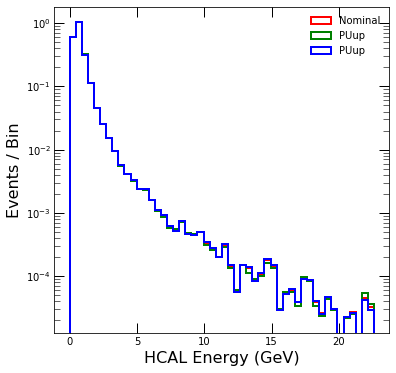

In [18]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [binx/1200-0.02 for binx in range(51)]
#binsx = [binx+50 for binx in range(101)]

#highScoreOffHist = offPlot.hist(highScoreOffPeak['nCloseHitsStation_3'],density=True,label='Off Peak Events Score >0.4',histtype='step',bins=10,linewidth=2, color='black')
lowScoreOffHist = offPlot.hist(lowScoreMC['HEDepth_4'],density=True,label='Nominal',histtype='step',bins=50,linewidth=2, color='red',weights=lowScoreMC['EventWeight'])
puUpHist = offPlot.hist(lowScoreMC['HEDepth_4'],density=True,label='PUup',histtype='step',bins=lowScoreOffHist[1],linewidth=2, color='green',weights=lowScoreMC['EventWeight']*lowScoreMC['PUupWeight'])
puDownHist = offPlot.hist(lowScoreMC['HEDepth_4'],density=True,label='PUup',histtype='step',bins=lowScoreOffHist[1],linewidth=2, color='blue',weights=lowScoreMC['EventWeight']*lowScoreMC['PUdownWeight'])

plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("HCAL Energy (GeV)",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

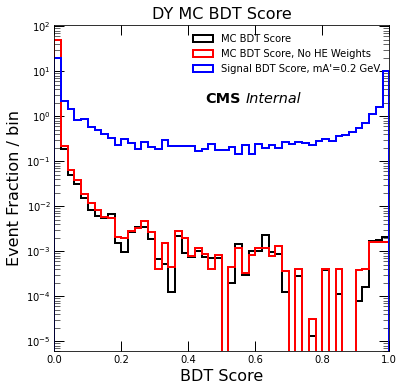

In [19]:
fig, predPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
#mcHist = predPlot.hist(allBDTs['BDTScore'],density=True,label='MC BDT Score',histtype='step',bins=50,linewidth=2, color='black')
mcHist = predPlot.hist(mc_preds,density=True,label='MC BDT Score',histtype='step',bins=50,linewidth=2, color='black', weights=weightedMCInputs['EventWeight'])
mcNoHEWeight = predPlot.hist(mc_preds,density=True,label='MC BDT Score, No HE Weights',histtype='step',bins=50,linewidth=2, color='red', weights=weightedMCInputs['EventWeight']/weightedMCInputs['HEWeight'])
sigHist = predPlot.hist(sig_preds,density=True, label='Signal BDT Score, mA\'=0.2 GeV', histtype='step', bins=50, linewidth=2, color='blue')
plt.yscale("log")
plt.title('DY MC BDT Score',fontsize=16)
plt.xlabel('BDT Score',fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
tx = predPlot.text(0.45, 2, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(0.57, 2, "Internal", size="x-large",style='italic')
plt.xlim([0.,1.])
plt.savefig("plots/mcBDTScore.pdf")
plt.show()

In [20]:
passSig = scoredMC[scoredMC['BDTScore']>0.98]
passSig.shape[0]/scoredMC.shape[0]
print(sum(passSig['EventWeight'])/sum(scoredMC['EventWeight']))
print(sum(passSig['EventWeight']/passSig['HEWeight'])/sum(scoredMC['EventWeight']/scoredMC['HEWeight']))

8.462495825060069e-05
8.088785845570293e-05


In [21]:
passHighHcalSig = scoredHighHcalMC[scoredHighHcalMC['BDTScore']>0.98]
print(passHighHcalSig.shape[0]/scoredHighHcalMC.shape[0])
passHighHcalDataSig = scoredHighHcalData[scoredHighHcalData['BDTScore']>0.98]
print(passHighHcalDataSig.shape[0]/scoredHighHcalData.shape[0])

0.058084239130434784
0.04348781023500988


In [22]:
HEWeightFrac = sum(passSig['EventWeight'])/sum(weightedMCInputs['EventWeight'])
noHEWeightFrac = sum(passSig['EventWeight']/passSig['HEWeight'])/sum(weightedMCInputs['EventWeight']/weightedMCInputs['HEWeight'])
print(HEWeightFrac)
print(noHEWeightFrac/HEWeightFrac)

8.46995260327416e-05
0.955815801682543


In [23]:
def findCloseHits(dataframe, dr):
    counts = [0] * dataframe.shape[0]

    for station in range(0,4):
        for idx, entry in enumerate(dataframe['cscDRbyStation_'+str(station)]):
            if entry < dr and entry>-0.1:
                counts[idx] = counts[idx] + 1
        
    return counts

In [24]:
def findCloseToFirstHits(dataframe, dr):
    counts = [0] * dataframe.shape[0]

    for station in range(1,4):
        dphi2 = (dataframe['cscDPhibyStation_0']-dataframe['cscDPhibyStation_'+str(station)])**2
        deta2 = (dataframe['cscDEtabyStation_0']-dataframe['cscDEtabyStation_'+str(station)])**2
        dr2 = dphi2+deta2
        for idx, entry in enumerate(dr2):
            if entry < dr**2 and dataframe['cscDPhibyStation_0'].iloc[idx]>-0.9:
                counts[idx] = counts[idx] + 1
    return counts

In [95]:
means = (offPeakData['cscDPhibyStation_0']+offPeakData['cscDPhibyStation_1']+offPeakData['cscDPhibyStation_2']+offPeakData['cscDPhibyStation_3'])/4.
stdev = (offPeakData['cscDPhibyStation_0']-means)**2+(offPeakData['cscDPhibyStation_1']-means)**2+(offPeakData['cscDPhibyStation_2']-means)**2+(offPeakData['cscDPhibyStation_3']-means)**2
offPeakData['stddev'] = stdev
means = (sigEvents['cscDPhibyStation_0']+sigEvents['cscDPhibyStation_1']+sigEvents['cscDPhibyStation_2']+sigEvents['cscDPhibyStation_3'])/4.
stdev = (sigEvents['cscDPhibyStation_0']-means)**2+(sigEvents['cscDPhibyStation_1']-means)**2+(sigEvents['cscDPhibyStation_2']-means)**2+(sigEvents['cscDPhibyStation_3']-means)**2
sigEvents['stddev'] = stdev
means = (lowScoreMC['cscDPhibyStation_0']+lowScoreMC['cscDPhibyStation_1']+lowScoreMC['cscDPhibyStation_2']+lowScoreMC['cscDPhibyStation_3'])/4.
stdev = (lowScoreMC['cscDPhibyStation_0']-means)**2+(lowScoreMC['cscDPhibyStation_1']-means)**2+(lowScoreMC['cscDPhibyStation_2']-means)**2+(lowScoreMC['cscDPhibyStation_3']-means)**2
lowScoreMC['stddev'] = stdev
dr = 0.05
mcCloseHits = findCloseToFirstHits(lowScoreMC,dr)
sigCloseHits = findCloseToFirstHits(sigEvents,dr)
offCloseHits = findCloseToFirstHits(offPeakData,dr)
dataCloseHits = findCloseToFirstHits(lowScoreData,dr)
highHcalMCCloseHits = findCloseToFirstHits(scoredHighHcalMC,dr)
highHcalDataCloseHits = findCloseToFirstHits(scoredHighHcalData,dr)
sameSignHighHcalCloseHits = findCloseToFirstHits(scoredSameSignHighHcal,dr)
lowScoreMC['closeHits'] = mcCloseHits
offPeakData['closeHits'] = offCloseHits
sigEvents['closeHits'] = sigCloseHits
lowScoreData['closeHits'] = dataCloseHits
scoredHighHcalMC['closeHits']=highHcalMCCloseHits
scoredHighHcalData['closeHits']=highHcalDataCloseHits
scoredSameSignHighHcal['closeHits']=sameSignHighHcalCloseHits
highScoreOffPeak = offPeakData[offPeakData['BDTScore']>0.4].copy()
highScoreSig = sigEvents[sigEvents['BDTScore']>0.4].copy()

In [26]:
def calcAvgDPhi(dataframe):
    dphis = [-10] * dataframe.shape[0]
    counts = [1] * dataframe.shape[0]

    for station in range(1,3):
        for idx, entry in enumerate(dataframe['cscDPhibyStation_'+str(station)]):
            if entry > -0.9:
                if dphis[idx] < -9:
                    dphis[idx] = entry
                else:
                    dphis[idx] = dphis[idx]+entry
                    counts[idx] = counts[idx] + 1
    for idx, entry in enumerate(dphis):
        dphis[idx] = dphis[idx]/counts[idx]
        
    return dphis

In [27]:
for station in range(4):
    newCSCDrs = []
    for entry in lowScoreData['cscDRbyStation_'+str(station)]:
        if entry>2:
            newCSCDrs.append(-1)
        else:
            newCSCDrs.append(entry)
    lowScoreData['cscDRbyStation_'+str(station)]=newCSCDrs
    newCSCDrs = []
    for entry in allBDTs['cscDRbyStation_'+str(station)]:
        if entry>2:
            newCSCDrs.append(-1)
        else:
            newCSCDrs.append(entry)
    allBDTs['cscDRbyStation_'+str(station)]=newCSCDrs

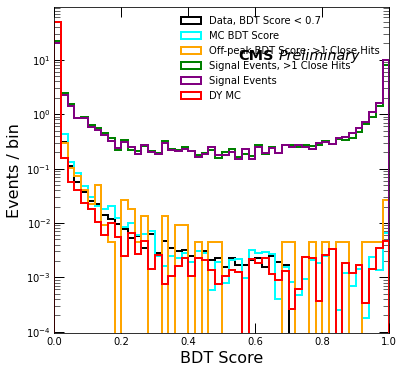

In [96]:
cscDiffCut = 0.02
mcDphi = calcAvgDPhi(lowScoreMC)
sigDphi = calcAvgDPhi(sigEvents)
offDphi = calcAvgDPhi(offPeakData)
dataDphi = calcAvgDPhi(lowScoreData)
sameSignDphi = calcAvgDPhi(sameSignData)

#lowStdMC = lowScoreMC[abs(mcDphi-lowScoreMC['cscDPhibyStation_0'])<cscDiffCut]
#lowStdSig = sigEvents[abs(sigDphi-sigEvents['cscDPhibyStation_0'])<cscDiffCut]
#lowStdOff = offPeakData[abs(offDphi-offPeakData['cscDPhibyStation_0'])<cscDiffCut]
#lowStdData = lowScoreData[abs(dataDphi-lowScoreData['cscDPhibyStation_0'])<cscDiffCut]
lowStdSameSign = sameSignData[abs(sameSignDphi-sameSignData['cscDPhibyStation_0'])<cscDiffCut]
lowStdMC = lowScoreMC[lowScoreMC['closeHits']>1]
lowStdSig = sigEvents[sigEvents['closeHits']>1]
lowStdOff = offPeakData[offPeakData['closeHits']>1]
lowStdData = lowScoreData[lowScoreData['closeHits']>1]

fig, predPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
histMax = 1
nbins = 50
binsx = [binx*histMax/nbins for binx in range(nbins+1)]
#mcScale = 398*58.6*1000*
lowScoreHist = predPlot.hist(lowStdData['BDTScore'],density=True,label='Data, BDT Score < 0.7',histtype='step',bins=binsx,linewidth=2, color='black', weights=lowStdData['EventWeight'])
#lowScoreHist = predPlot.hist(lowScoreData['BDTScore'],density=True,label='Data BDT Score',histtype='step',bins=binsx,linewidth=2, color='red', weights=lowScoreData['EventWeight'])
#mcHist = predPlot.hist(lowScoreMC['BDTScore'],density=True,label='MC BDT Score',histtype='step',bins=binsx,linewidth=2, color='blue',weights=lowScoreMC['EventWeight'])
mcHist = predPlot.hist(lowStdMC['BDTScore'],density=True,label='MC BDT Score',histtype='step',bins=binsx,linewidth=2, color='cyan',weights=lowStdMC['EventWeight'])
offPeakHist = predPlot.hist(lowStdOff['BDTScore'],density=True,label='Off-peak BDT Score, >1 Close Hits',histtype='step',bins=binsx,linewidth=2, color='orange', weights=lowStdOff['EventWeight'])
#allOffPeakHist = predPlot.hist(offPeakData['BDTScore'],density=True,label='Off-peak BDT Score',histtype='step',bins=binsx,linewidth=2, color='cyan', weights=offPeakData['EventWeight']/0.52)
sigHist = predPlot.hist(lowStdSig['BDTScore'],density=True,label='Signal Events, >1 Close Hits',histtype='step',bins=binsx,linewidth=2, color='green', weights=lowStdSig['EventWeight']/0.52)
allSigHist = predPlot.hist(sigEvents['BDTScore'],density=True,label='Signal Events',histtype='step',bins=binsx,linewidth=2, color='purple', weights=sigEvents['EventWeight']/0.52)
#sameSignHist = predPlot.hist(scoredSameSignHighHcal['BDTScore'],density=True,label='Same-sign BDT Score',histtype='step',bins=binsx,linewidth=2, color='green')
#lowStdSameSignHist =  predPlot.hist(lowStdSameSign['BDTScore'],density=True,label='Same-sign BDT Score',histtype='step',bins=binsx,linewidth=2, color='yellow', weights=lowStdSameSign['EventWeight'])
mcHist = predPlot.hist(allBDTs['BDTScore'],density=True,label='DY MC',histtype='step',bins=binsx,linewidth=2, color='red',weights=allBDTs['trainingWeight'])

plt.yscale("log")
#plt.title('Low Score Data Events, CSC $\Delta$R<0.01',fontsize=16)
plt.xlabel('BDT Score',fontsize=16)
plt.ylabel('Events / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
leg_x = 0.55
tx = predPlot.text(leg_x, 10, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(leg_x+0.12, 10, "Preliminary", size="x-large",style='italic')
plt.xlim([0.,1.])
plt.savefig("plots/partialBDTScore.pdf")
plt.show()

In [99]:
#lowStdOff['BDTScore']
#lowStdSig['BDTScore']
#print(lowStdMC.shape[0])
passSigMC = lowStdMC[lowStdMC['BDTScore']>0.98]
passSigSig = lowStdSig[lowStdSig['BDTScore']>0.98]
passSigOff = lowStdOff[lowStdOff['BDTScore']>0.98]

15 721 6


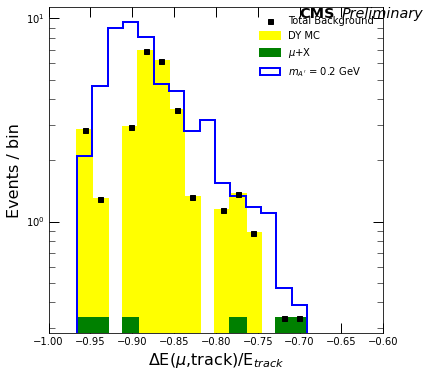

In [161]:
fig, predPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
histMax = 1
nbins = 50
#binsx = [binx*histMax/nbins for binx in range(nbins+1)]
binsx=15
nOffPeak = 2
nDy = 27
sumBkg = np.append(passSigOff['standaloneDEoverE'],passSigMC['standaloneDEoverE'])
sumBkgWeight = np.append(passSigOff['EventWeight']*nOffPeak/sum(passSigOff['EventWeight']),passSigMC['EventWeight']*nDy/sum(passSigMC['EventWeight']))
mcHist = predPlot.hist(sumBkg,density=False,label='DY MC',histtype='step',bins=binsx,linewidth=2, color='yellow',weights=sumBkgWeight,fill=True)
offPeakHist = predPlot.hist(passSigOff['standaloneDEoverE'],density=False,label='$\mu$+X',histtype='step',bins=mcHist[1],linewidth=2, color='green',weights=passSigOff['EventWeight']*nOffPeak/sum(passSigOff['EventWeight']),fill=True)
sumHist = np.histogram(sumBkg,density=False,bins=binsx,weights=sumBkgWeight)
sigHist =  predPlot.hist(passSigSig['standaloneDEoverE'],density=True,label='$m_{A\'}~$= 0.2 GeV',histtype='step',bins=mcHist[1],linewidth=2, color='blue',weights=passSigSig['EventWeight'])
shiftX = [ val+(sumHist[1][1]-sumHist[1][0])/2. for val in sumHist[1][:-1]]
predPlot.plot(shiftX,sumHist[0],color='black',marker='s',linestyle='none',markersize=5,label='Total Background',)
plt.yscale("log")
#plt.title('Low Score Data Events, CSC $\Delta$R<0.01',fontsize=16)
plt.xlabel('$\Delta$E($\mu$,track)/E$_{track}$',fontsize=16)
plt.ylabel('Events / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
leg_x = -0.7
tx = predPlot.text(leg_x, 10, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(leg_x+0.05, 10, "Preliminary", size="x-large",style='italic')
plt.xlim([-1.,-0.6])
plt.savefig("plots/partDisStaDEoverE.pdf")
plt.show()

In [29]:
print(lowStdOff[lowStdOff['BDTScore']>0.96].shape[0])
print(sameSignData[sameSignData['BDTScore']>0.98].shape[0])
print(lowStdSig.shape[0]/sigEvents.shape[0])
print((lowStdSig[lowStdSig['BDTScore']>0.98].shape[0]/lowStdSig.shape[0])/(sigEvents[sigEvents['BDTScore']>0.98].shape[0]/sigEvents.shape[0]))
print(sigEvents[sigEvents['BDTScore']>0.98].shape[0]/sigEvents.shape[0])
print("MC difference:")
print(lowStdMC.shape[0]/lowScoreMC.shape[0])
print(sum(lowStdMC['EventWeight']))
print(sum(lowScoreMC['EventWeight']))
print(lowStdOff.shape[0]/offPeakData.shape[0])
print("Data diff:")
print(lowStdData.shape[0]/lowScoreData.shape[0])
print(lowStdData.shape[0])
print(lowScoreData.shape[0])
print(lowStdSameSign[lowStdSameSign['BDTScore']>0.96].shape[0])
print(lowStdOff[lowStdOff['BDTScore']>0.4].shape[0]/offPeakData[offPeakData['BDTScore']>0.4].shape[0])
print(highScoreOffPeak[highScoreOffPeak['closeHits']>1].shape[0]/highScoreOffPeak.shape[0])
passingMC=lowStdMC[lowStdMC['BDTScore']>0.98]
print("HE Weight Systematic:")
print(sum(passingMC['EventWeight'])/sum(lowStdMC['EventWeight']))
print(sum(passingMC['EventWeight']/passingMC['HEWeight'])/sum(lowStdMC['EventWeight']/lowStdMC['HEWeight']))

7
2
0.8675754625121713
0.8006277720471683
0.2021421616358325
MC difference:
0.9228188188188188
178806.09074098666
194120.37785426824
0.6513434579439252
Data diff:
0.6500745532369457
262896
404409
1
0.12080536912751678
0.12080536912751678
HE Weight Systematic:
1.017151150842699e-05
1.750678920576e-05


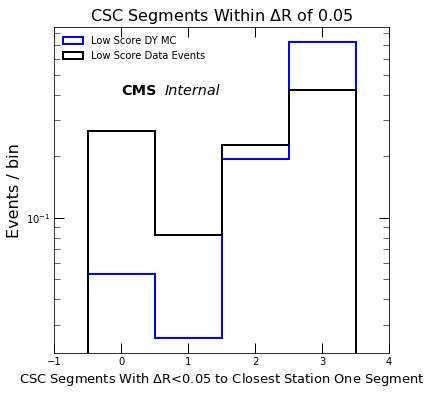

In [44]:
fig, predPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
histMax = 5
nbins = 5
binsx = [binx*histMax/nbins-0.5 for binx in range(nbins+1)]
#mcScale = 398*58.6*1000*
#lowScoreHist = predPlot.hist(lowScoreData['closeHits'],density=True,label='Data N Close Hits',histtype='step',bins=binsx,linewidth=2, color='red', weights=lowScoreData['EventWeight'])
mcHist = predPlot.hist(lowScoreMC['closeHits'],density=True,label='Low Score DY MC',histtype='step',bins=binsx,linewidth=2, color='blue',weights=lowScoreMC['EventWeight'])
#mcHist = predPlot.hist(lowStdMC['BDTScore'],density=True,label='MC BDT Score',histtype='step',bins=binsx,linewidth=2, color='cyan',weights=lowStdMC['EventWeight'])
#offPeakHist = predPlot.hist(offPeakData['closeHits'],density=True,label='Off-peak Events',histtype='step',bins=binsx,linewidth=2, color='orange', weights=offPeakData['EventWeight'])
highOffPeakHist = predPlot.hist(lowScoreData['closeHits'],density=True,label='Low Score Data Events',histtype='step',bins=binsx,linewidth=2, color='black')
#allSigHist = predPlot.hist(sigEvents['closeHits'],density=True,label='Signal Events',histtype='step',bins=binsx,linewidth=2, color='purple', weights=sigEvents['EventWeight'])
#highSigHist = predPlot.hist(highScoreSig['closeHits'],density=True,label='High-Score Signal Events',histtype='step',bins=binsx,linewidth=2, color='purple', weights=highScoreSig['EventWeight'])
#sameSignHist = predPlot.hist(sameSignData['BDTScore'],density=True,label='Same-sign BDT Score',histtype='step',bins=binsx,linewidth=2, color='green', weights=sameSignData['EventWeight'])
#lowStdSameSignHist =  predPlot.hist(lowStdSameSign['BDTScore'],density=True,label='Same-sign BDT Score',histtype='step',bins=binsx,linewidth=2, color='yellow', weights=lowStdSameSign['EventWeight'])
#mcHist = predPlot.hist(lowScoreMC['closeHits'],density=True,label='DY MC',histtype='step',bins=binsx,linewidth=2, color='cyan',weights=lowScoreMC['EventWeight'])

plt.yscale("log")
plt.title('CSC Segments Within $\Delta$R of 0.05',fontsize=16)
plt.xlabel('CSC Segments With $\Delta$R<0.05 to Closest Station One Segment',fontsize=13)
plt.ylabel('Events / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper left')
leg.get_frame().set_alpha(0)
tx = predPlot.text(0, 0.4, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(0.65, 0.4, "Internal", size="x-large",style='italic')
plt.xlim([-1.,4.])
plt.savefig("plots/partialCloseHits.pdf")
plt.show()

In [30]:
for station in range(4):
    newCSCDrs = []
    for entry in lowStdData['cscDRbyStation_'+str(station)]:
        if entry>2:
            newCSCDrs.append(-1)
        else:
            newCSCDrs.append(entry)
    lowStdData['cscDRbyStation_'+str(station)]=newCSCDrs

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  


In [31]:
means = (highScoreOffPeak['cscDPhibyStation_0']+highScoreOffPeak['cscDPhibyStation_1']+highScoreOffPeak['cscDPhibyStation_2']+highScoreOffPeak['cscDPhibyStation_3'])/4.
stdev = (highScoreOffPeak['cscDPhibyStation_0']-means)**2+(highScoreOffPeak['cscDPhibyStation_1']-means)**2+(highScoreOffPeak['cscDPhibyStation_2']-means)**2+(highScoreOffPeak['cscDPhibyStation_3']-means)**2
highScoreOffPeak['stddev'] = stdev

In [32]:
means = (sigEvents['cscDPhibyStation_0']+sigEvents['cscDPhibyStation_1']+sigEvents['cscDPhibyStation_2']+sigEvents['cscDPhibyStation_3'])/4.
stdev = (sigEvents['cscDPhibyStation_0']-means)**2+(sigEvents['cscDPhibyStation_1']-means)**2+(sigEvents['cscDPhibyStation_2']-means)**2+(sigEvents['cscDPhibyStation_3']-means)**2
sigEvents['stddev'] = stdev

In [33]:
means = (lowScoreMC['cscDPhibyStation_0']+lowScoreMC['cscDPhibyStation_1']+lowScoreMC['cscDPhibyStation_2']+lowScoreMC['cscDPhibyStation_3'])/4.
stdev = (lowScoreMC['cscDPhibyStation_0']-means)**2+(lowScoreMC['cscDPhibyStation_1']-means)**2+(lowScoreMC['cscDPhibyStation_2']-means)**2+(lowScoreMC['cscDPhibyStation_3']-means)**2
lowScoreMC['stddev'] = stdev

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


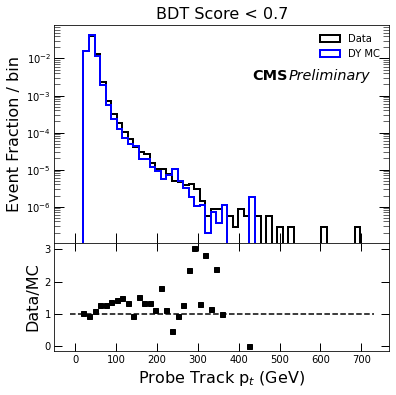

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


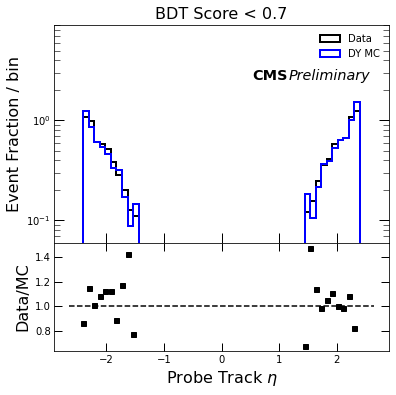

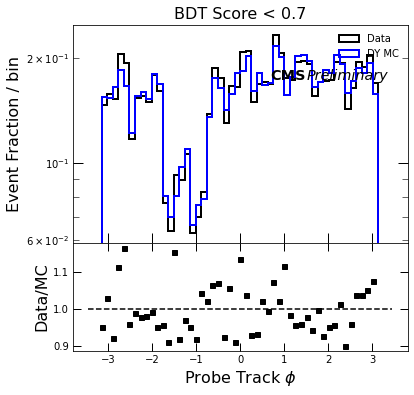

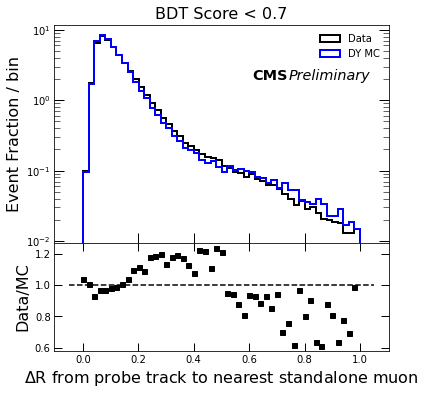

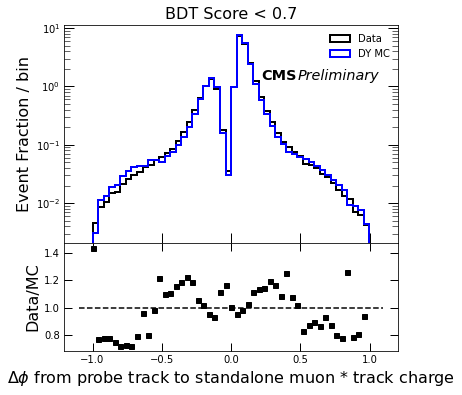

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


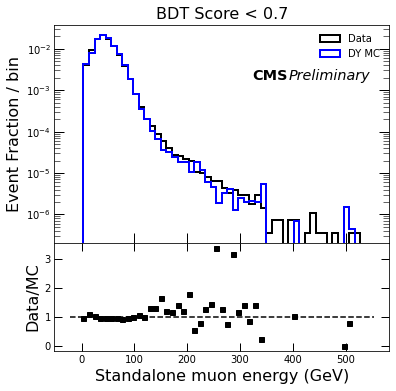

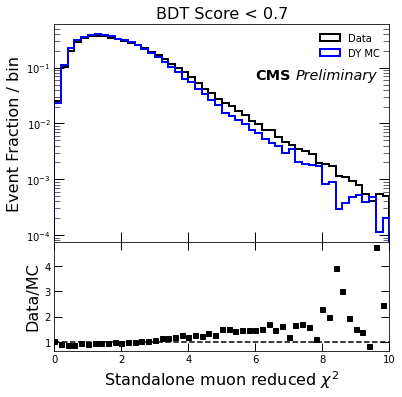

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


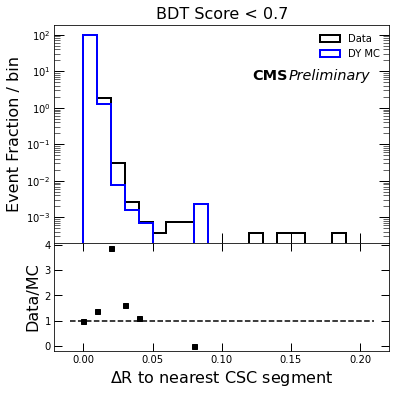

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide


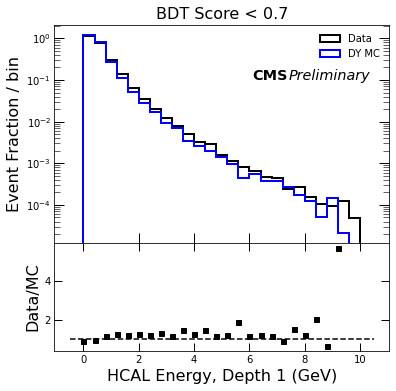

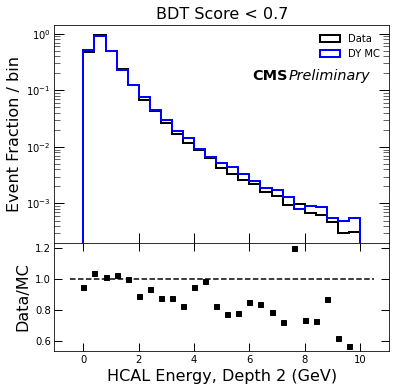

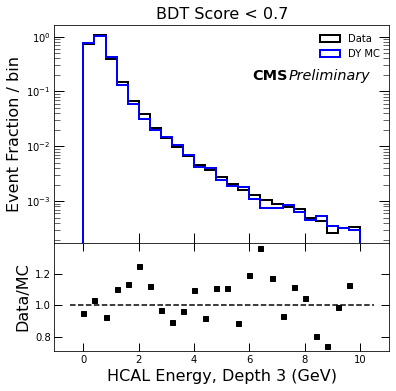

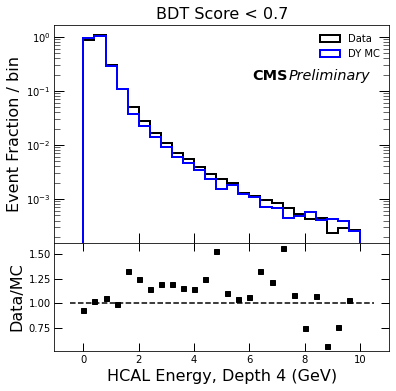

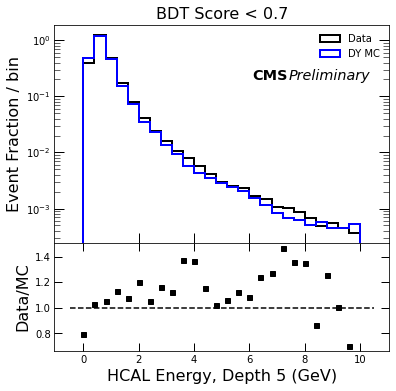

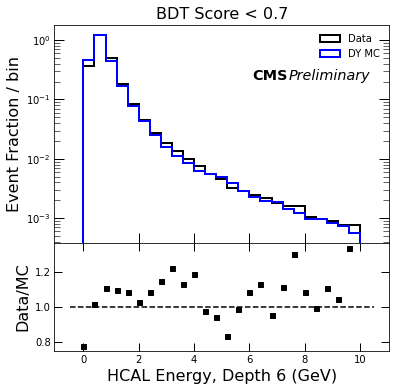

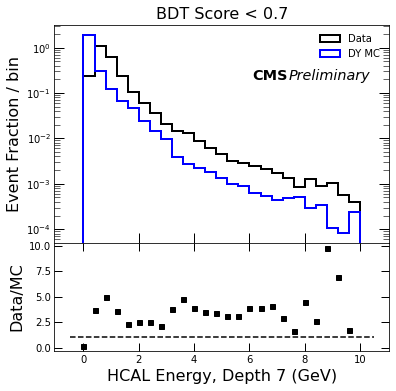

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


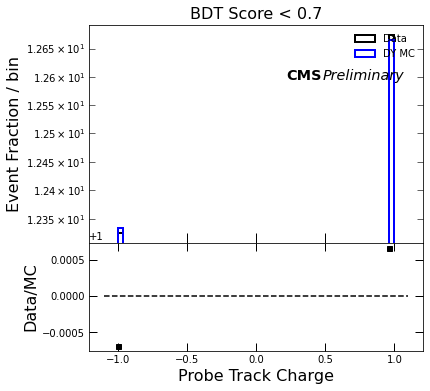

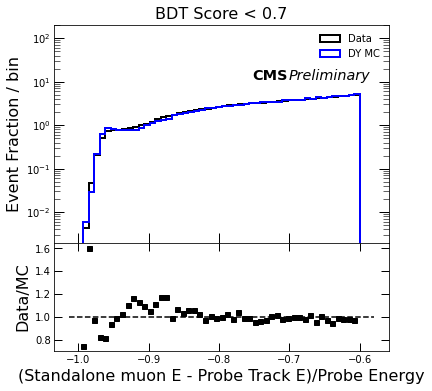

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


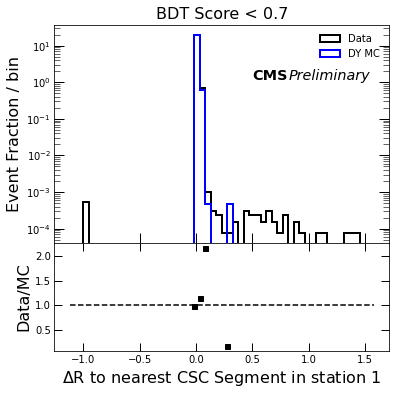

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


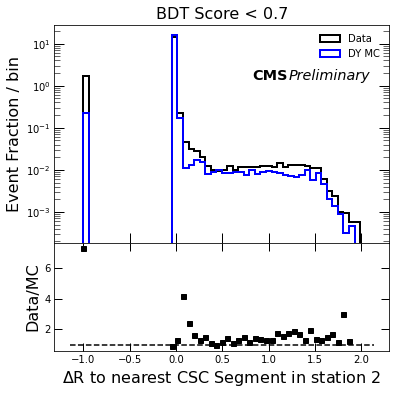

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: divide by zero encountered in true_divide
/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


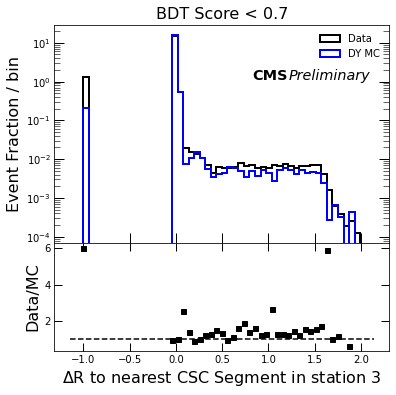

/home/rever025/.local/lib/python3.6/site-packages/ipykernel_launcher.py:47: RuntimeWarning: invalid value encountered in true_divide


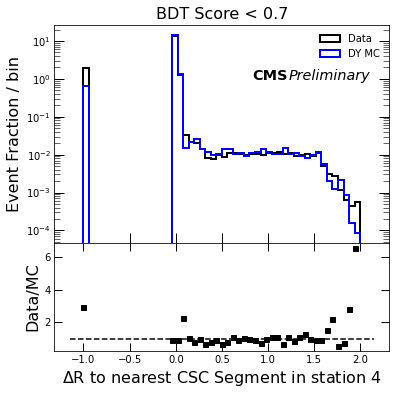

In [34]:
featLabels =  ["Probe Track p$_t$ (GeV)",
               "Probe Track $\eta$",
               "Probe Track $\phi$",
               "$\Delta$R from probe track to nearest standalone muon",
               "$\Delta\phi$ from probe track to standalone muon * track charge",
               "Standalone muon energy (GeV)",
               "Standalone muon reduced $\chi^2$",
               "$\Delta$R to nearest CSC segment",
               "HCAL Energy, Depth 1 (GeV)",
               "HCAL Energy, Depth 2 (GeV)",
               "HCAL Energy, Depth 3 (GeV)",
               "HCAL Energy, Depth 4 (GeV)",
               "HCAL Energy, Depth 5 (GeV)",
               "HCAL Energy, Depth 6 (GeV)",
               "HCAL Energy, Depth 7 (GeV)",
               "Probe Track Charge",
               "(Standalone muon E - Probe Track E)/Probe Energy",
               "$\Delta$R to nearest CSC Segment in station 1",
               "$\Delta$R to nearest CSC Segment in station 2",
               "$\Delta$R to nearest CSC Segment in station 3",
               "$\Delta$R to nearest CSC Segment in station 4"]
for idx, feature in enumerate(bdtfeatures):
    fig, (absolute, ratio) = plt.subplots(
        nrows=2,
        sharex = 'col', # have the columns share the x axis
        gridspec_kw = dict(
            hspace = 0.0, # shrink height space between the two figs
            height_ratios = [2,1]
        )
    )
    fig.set_figheight(6)
    if feature=='staChi':
        binsx = [10*binx/50. for binx in range(51)]
    elif feature=='cscDR':
        binsx = [binx/100. for binx in range(21)]
    else:
        binsx = 50
    if 'HEDepth' in feature:
        binsx = [10*binx/25. for binx in range(26)]
    lowScoreHist = absolute.hist(lowStdData[feature],density=True,label='Data',histtype='step',bins=binsx,linewidth=2, color='black', weights=lowStdData['EventWeight'])
    lowScoreMCHist = absolute.hist(lowStdMC[feature],bins=lowScoreHist[1],density=True,label='DY MC',histtype='step',linewidth=2, color='blue', weights=lowStdMC['EventWeight'])
    #offPeakHist = absolute.hist(lowStdOff[feature],density=True,label='High Score Off-Peak Events',histtype='step',bins=lowScoreHist[1],linewidth=2, color='red', weights=lowStdOff['EventWeight'])
    #sigHist = absolute.hist(lowStdSig[feature],bins=lowScoreHist[1],density=True,label='mAp 0p2 GeV',histtype='step',linewidth=2, color='green', weights=lowStdSig['EventWeight'])
    absolute.set_yscale('log')
    absolute.set_ylabel('Event Fraction / bin',fontsize=16)
    absolute.legend()
    ratioHist = lowScoreHist[0]/lowScoreMCHist[0]
    ratio.plot(lowScoreHist[1][:-1],ratioHist,color='black',marker='s',linestyle='none',markersize=5)
    ratio.set_ylabel('Data/MC',fontsize=16)

    leg=absolute.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
    if feature=='staChi':
        ratio.set_xlim([0, 10])
    if feature=='eta':
        absolute.set_ylim(0.06, 9)
    if feature=='standaloneDEoverE':
        absolute.set_ylim(0.002,200)
    yrange = absolute.get_ylim()
    xrange = absolute.get_xlim()
    tx = absolute.text(xrange[0]+(xrange[1]-xrange[0])*0.6,yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),  "CMS", size="x-large",weight='bold')
    tx2 = absolute.text(xrange[0]+(xrange[1]-xrange[0])*0.72, yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),"Preliminary", size="x-large",style='italic')
    absolute.tick_params(direction='in', length=10, width=1)
    absolute.tick_params(which='minor', direction='in',length=6)
    absolute.yaxis.set_ticks_position('both')
    absolute.set_title('BDT Score < 0.7',fontsize=16)
    #absolute.set_ylim([0.0005,2.2])
    ratio.set_xlabel(featLabels[idx],fontsize=16)
    ratio.tick_params(direction='in', length=8, width=1)
    ratio.yaxis.set_ticks_position('both')
    ratio.xaxis.set_ticks_position('both')

    #ratio.set_ylim([0.7,1.3])
    x_points = ratio.get_xlim()
    y_points = [1, 1]
    ratio.plot(x_points, y_points, 'black',linestyle='dashed')
    plt.savefig("plots/lowScoreValid/partialRegion"+feature+".pdf")
    plt.show()

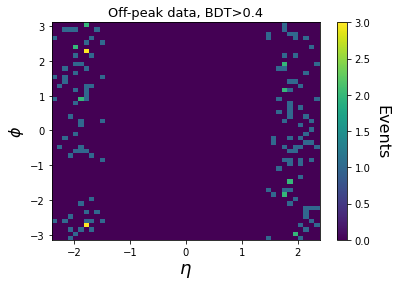

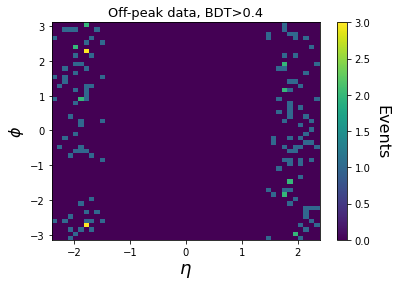

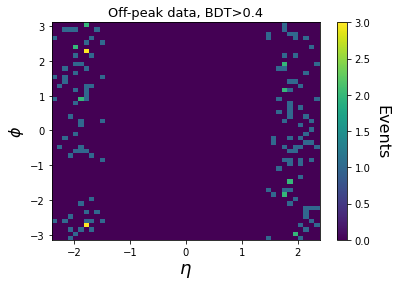

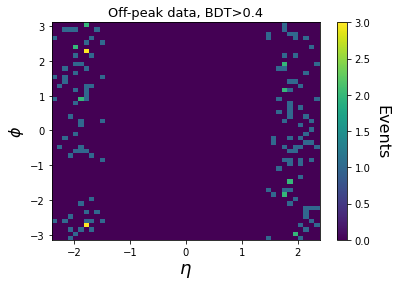

In [35]:
for station in range(4):
    farStaData = lowScoreData[lowScoreData['cscDRbyStation_'+str(station)]>0.1]
    h = plt.hist2d(highScoreOffPeak["eta"], highScoreOffPeak["phi"], bins=50, range=None, density=None, weights=None)
    plt.xlabel('$\eta$', fontsize=18)
    plt.ylabel('$\phi$', fontsize=16)
    plt.title('Off-peak data, BDT>0.4',fontsize=13)
    cbar = plt.colorbar(h[3])
    cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
    plt.savefig("posEtaEdgeEventsData.pdf")
    plt.show()

In [36]:
#negCSCoffPeak = highScoreOffPeak[((offPeakData['cscDEtabyStation_1'])>0)]
#for feature in allfeatures:
#    fig, offPlot = plt.subplots(
#            nrows=1
#        )
#    fig.set_figheight(6)
#    if "cscDPhibyStation" in feature:
#        highScoreHist = offPlot.hist(highScoreOffPeak[feature],density=True,label='Off-Peak Events, BDT Score>0.4',histtype='step',bins=50,linewidth=2, color='black')
#        mcHist = offPlot.hist(negCSCoffPeak[feature],density=True,label='High Score Off-Peak Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')
#        regOffHist = offPlot.hist(offPeakData[feature],density=True,label='Off-Peak Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')
#        sigHist = offPlot.hist(lowStdSig[feature],bins=highScoreHist[1],density=True,label='mAp 0p2 GeV',histtype='step',linewidth=2, color='red', weights=lowStdSig['EventWeight'])##

#    if "cscDEtabyStation" in feature:
#        binx = [i/50 - 1. for i in range(100)]
#        highScoreHist = offPlot.hist(highScoreOffPeak[feature],density=True,label='Off-Peak Events, BDT Score>0.4',histtype='step',bins=binx,linewidth=2, color='black')
#        mcHist = offPlot.hist(negCSCoffPeak[feature],density=True,label='High Score Off-Peak Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')
#        regOffHist = offPlot.hist(offPeakData[feature],density=True,label='Off-Peak Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')
#        sigHist = offPlot.hist(lowStdSig[feature],bins=highScoreHist[1],density=True,label='mAp 0p2 GeV',histtype='step',linewidth=2, color='red', weights=lowStdSig['EventWeight'])
        
#   else:
#       mcHist = offPlot.hist(highScoreOffPeak[feature],density=True,label='Off-Peak Events, BDT Score>0.4',histtype='step',bins=50,linewidth=2, color='black')
#       regOffHist = offPlot.hist(offPeakData[feature],density=True,label='Off-Peak Events',histtype='step',bins=mcHist[1],linewidth=2, color='blue')
#       mcHist = offPlot.hist(negCSCoffPeak[feature],density=True,label='High Score Off-Peak Events',histtype='step',bins=mcHist[1],linewidth=2, color='green')
#       sigHist = offPlot.hist(lowStdSig[feature],bins=mcHist[1],density=True,label='mAp 0p2 GeV',histtype='step',linewidth=2, color='red', weights=lowStdSig['EventWeight'])

#   plt.yscale("log")
#   plt.title('High Score Off-peak Events',fontsize=16)
#   plt.xlabel(feature,fontsize=16)
#   plt.ylabel('Event Fraction / bin',fontsize=16)
#   plt.tick_params(direction='in', length=10, width=1)
#   plt.tick_params(which='minor', direction='in',length=6)
#   offPlot.yaxis.set_ticks_position('both')
#   offPlot.xaxis.set_ticks_position('both')
#   leg=offPlot.legend(loc='upper right')
#   leg.get_frame().set_alpha(0)
    #tx = offPlot.text(0.45, 2, "CMS", size="x-large",weight='bold')
    #tx2 = offPlot.text(0.57, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
#   plt.show()

In [37]:
print(highScoreOffPeak['probeCharge'])
print(negCSCoffPeak['probeCharge'])

51       1.0
241     -1.0
339     -1.0
455     -1.0
480      1.0
        ... 
37215    1.0
38004   -1.0
38229   -1.0
38882    1.0
39064   -1.0
Name: probeCharge, Length: 149, dtype: float64


NameError: name 'negCSCoffPeak' is not defined

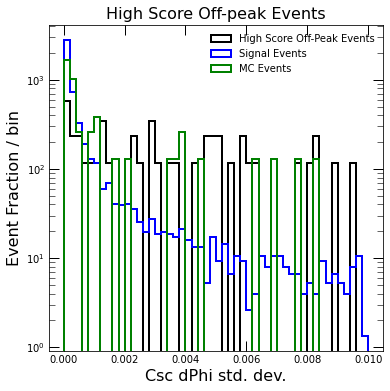

In [39]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [0.01*binx/50 for binx in range(51)]
noMissHigh = highScoreOffPeak[(abs(highScoreOffPeak['cscDPhibyStation_0'])<0.99)&(abs(highScoreOffPeak['cscDPhibyStation_1'])<0.99)&(abs(highScoreOffPeak['cscDPhibyStation_2'])<0.99)&(abs(highScoreOffPeak['cscDPhibyStation_3'])<0.99)]
noMissSig = sigEvents[(abs(sigEvents['cscDPhibyStation_0'])<0.99)&(abs(sigEvents['cscDPhibyStation_1'])<0.99)&(abs(sigEvents['cscDPhibyStation_2'])<0.99)&(abs(sigEvents['cscDPhibyStation_3'])<0.99)]
noMissMC = lowScoreMC[(abs(lowScoreMC['cscDPhibyStation_0'])<0.99)&(abs(lowScoreMC['cscDPhibyStation_1'])<0.99)&(abs(lowScoreMC['cscDPhibyStation_2'])<0.99)&(abs(lowScoreMC['cscDPhibyStation_3'])<0.99)&(lowScoreMC['BDTScore']>0.4)]
highScoreHist = offPlot.hist(noMissHigh['stddev'],density=True,label='High Score Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
regOffHist = offPlot.hist(noMissSig['stddev'],density=True,label='Signal Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')        
mcHist = offPlot.hist(noMissMC['stddev'],density=True,label='MC Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')     

plt.yscale("log")
plt.title('High Score Off-peak Events',fontsize=16)
plt.xlabel("Csc dPhi std. dev.",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [40]:
highScoreSigEvents = sigEvents[sigEvents['BDTScore']>0.98]
highCSCevents = offPeakData[(offPeakData['BDTScore']>0.4)]
binsx = [5*binx/50. for binx in range(51)]

minDeta = [10] * highCSCevents.shape[0]
minDphi = [10] * highCSCevents.shape[0]
sigMinDphi = [10] * highScoreSigEvents.shape[0]
for station in range(1,4):
    for idx, entry in enumerate(highCSCevents['cscDEtabyStation_'+str(station)]):
        if entry<minDeta[idx]:
            minDeta[idx] = entry
    for idx, entry in enumerate(highCSCevents['cscDPhibyStation_'+str(station)]):
        if abs(entry)<abs(minDphi[idx]):
            minDphi[idx] = entry        
    for idx, entry in enumerate(highScoreSigEvents['cscDPhibyStation_'+str(station)]):
        if abs(entry)<abs(sigMinDphi[idx]):
            sigMinDphi[idx] = entry

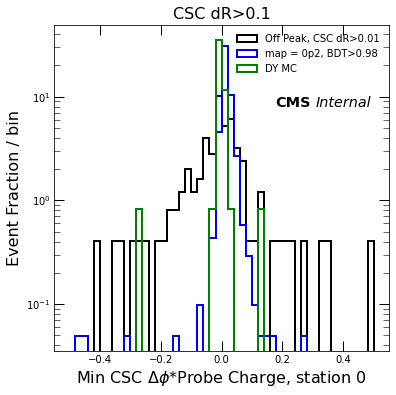

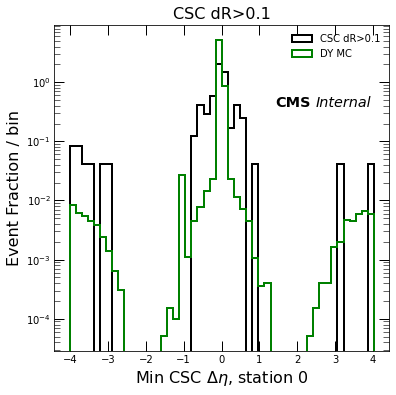

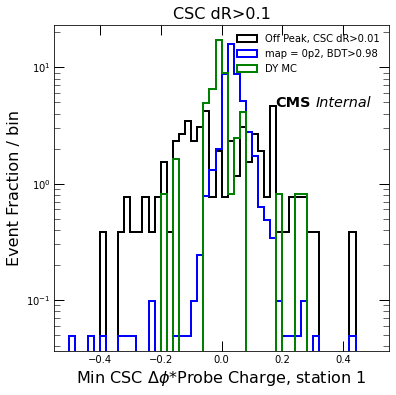

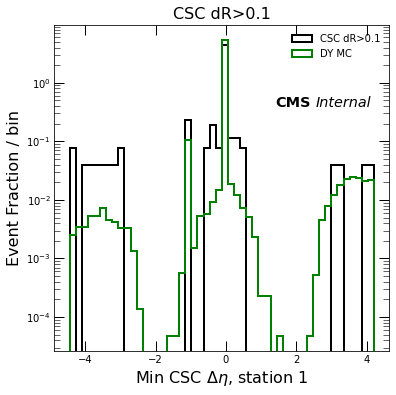

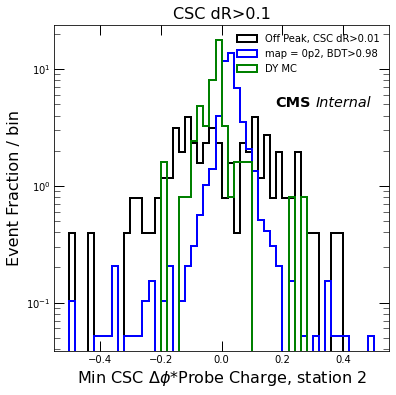

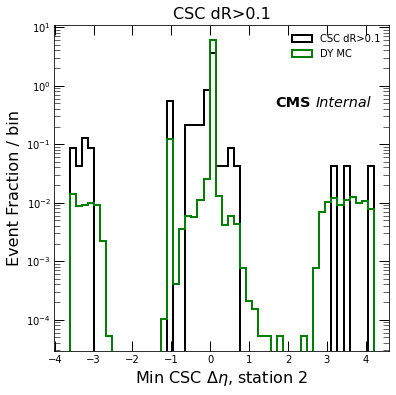

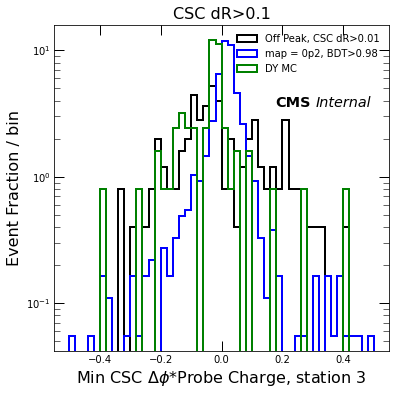

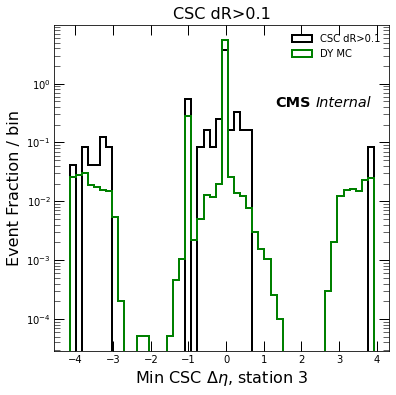

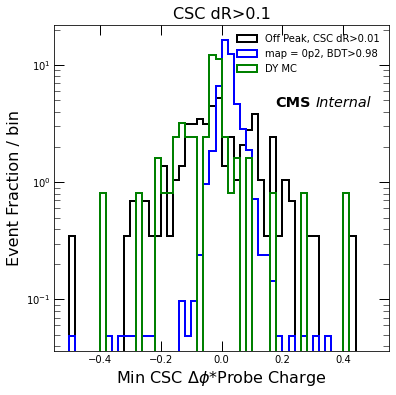

In [41]:

highScoreMC = scoredMC[scoredMC['BDTScore']>0.4]
maxVal = 1
nbins=50
cscBins = [maxVal*binx/nbins-maxVal/2 for binx in range(nbins+1)]
for station in range(4):
    fig, offPlot = plt.subplots(
            nrows=1
        )
    fig.set_figheight(6)
    mcHist = offPlot.hist(highCSCevents['cscDPhibyStation_'+str(station)]*highCSCevents['probeCharge'],density=True,label='Off Peak, CSC dR>0.01',histtype='step',bins=cscBins,linewidth=2, color='black')
    sigHist = offPlot.hist(highScoreSigEvents['cscDPhibyStation_'+str(station)]*highScoreSigEvents['probeCharge'],density=True,label='map = 0p2, BDT>0.98',histtype='step',bins=cscBins,linewidth=2, color='blue')
    baseMcHist = offPlot.hist(highScoreMC['cscDPhibyStation_'+str(station)]*highScoreMC['probeCharge'],density=True,label='DY MC',histtype='step',bins=cscBins,linewidth=2, color='green')
    #highScoreSigEvents['probeCharge']
    plt.yscale("log")
    plt.title('CSC dR>0.1',fontsize=16)
    plt.xlabel("Min CSC $\Delta\phi$*Probe Charge, station "+str(station),fontsize=16)
    plt.ylabel('Event Fraction / bin',fontsize=16)
    plt.tick_params(direction='in', length=10, width=1)
    plt.tick_params(which='minor', direction='in',length=6)
    offPlot.yaxis.set_ticks_position('both')
    offPlot.xaxis.set_ticks_position('both')
    leg=offPlot.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
    yrange = offPlot.get_ylim()
    xrange = offPlot.get_xlim()
    tx = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.66,yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),  "CMS", size="x-large",weight='bold')
    tx2 = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.78, yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),"Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
    plt.show()
    fig, offPlot = plt.subplots(
         nrows=1
    )
    fig.set_figheight(6)
    mcEtaHist = offPlot.hist(highCSCevents['cscDEtabyStation_'+str(station)],density=True,label='CSC dR>0.1',histtype='step',bins=50,linewidth=2, color='black')
    #sigEtaHist = offPlot.hist(highScoreSigEvents['cscDEtabyStation_'+str(station)],density=True,label='map = 0p2',histtype='step',bins=mcEtaHist[1],linewidth=2, color='blue')
    baseMcHist = offPlot.hist(mcEvents['cscDEtabyStation_'+str(station)],density=True,label='DY MC',histtype='step',bins=mcEtaHist[1],linewidth=2, color='green')

    plt.yscale("log")
    plt.title('CSC dR>0.1',fontsize=16)
    plt.xlabel("Min CSC $\Delta\eta$, station "+str(station),fontsize=16)
    plt.ylabel('Event Fraction / bin',fontsize=16)
    plt.tick_params(direction='in', length=10, width=1)
    plt.tick_params(which='minor', direction='in',length=6)
    offPlot.yaxis.set_ticks_position('both')
    offPlot.xaxis.set_ticks_position('both')
    leg=offPlot.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
    yrange = offPlot.get_ylim()
    xrange = offPlot.get_xlim()
    tx = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.66,yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),  "CMS", size="x-large",weight='bold')
    tx2 = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.78, yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),"Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
    plt.show()
    #h = plt.hist2d(highCSCevents["cscDPhibyStation_"+str(station)], highCSCevents["cscDEtabyStation_"+str(station)], bins=100, range=None, density=None, weights=None)
    #plt.xlabel('$\Delta\phi$', fontsize=18)
    #plt.ylabel('$\Delta\eta$', fontsize=16)
    #plt.title('Station '+str(station),fontsize=13)
    #plt.xlim([-0.5,0.5])
    #plt.ylim([-0.5,0.5])
    #cbar = plt.colorbar(h[3])
    #cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
    #plt.savefig("posEtaEdgeEventsData.pdf")
    #plt.show()
    #h = plt.hist2d(highScoreSigEvents["cscDPhibyStation_"+str(station)], highScoreSigEvents["cscDEtabyStation_"+str(station)], bins=100, range=None, density=None, weights=None)
    #plt.xlabel('$\Delta\phi$', fontsize=18)
    #plt.ylabel('$\Delta\eta$', fontsize=16)
    #plt.title('Station '+str(station),fontsize=13)
    #plt.xlim([-0.5,0.5])
    #plt.ylim([-0.5,0.5])
    #cbar = plt.colorbar(h[3])
    #cbar.ax.set_ylabel("Events", rotation=-90, va="bottom", fontsize=16)
    #plt.savefig("posEtaEdgeEventsData.pdf")
    #plt.show()
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
mcHist = offPlot.hist(minDphi*highCSCevents['probeCharge'],density=True,label='Off Peak, CSC dR>0.01',histtype='step',bins=cscBins,linewidth=2, color='black')
sigHist = offPlot.hist(sigMinDphi*highScoreSigEvents['probeCharge'],density=True,label='map = 0p2, BDT>0.98',histtype='step',bins=cscBins,linewidth=2, color='blue')
baseMcHist = offPlot.hist(scoredMC[scoredMC['BDTScore']>0.4]['cscDPhibyStation_'+str(station)]*mcEvents['probeCharge'],density=True,label='DY MC',histtype='step',bins=cscBins,linewidth=2, color='green')
    #highScoreSigEvents['probeCharge']
plt.yscale("log")
plt.title('CSC dR>0.1',fontsize=16)
plt.xlabel("Min CSC $\Delta\phi$*Probe Charge",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
yrange = offPlot.get_ylim()
xrange = offPlot.get_xlim()
tx = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.66,yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),  "CMS", size="x-large",weight='bold')
tx2 = offPlot.text(xrange[0]+(xrange[1]-xrange[0])*0.78, yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),"Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

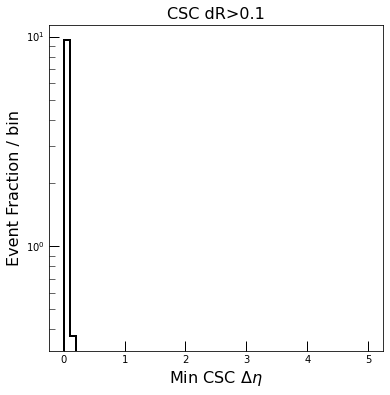

In [42]:
fig, offPlot = plt.subplots(
       nrows=1
  )
fig.set_figheight(6)
mcHist = offPlot.hist(minDeta,density=True,label='CSC dR>0.1',histtype='step',bins=binsx,linewidth=2, color='black')
plt.yscale("log")
plt.title('CSC dR>0.1',fontsize=16)
plt.xlabel("Min CSC $\Delta\eta$",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
tx = predPlot.text(0.45, 2, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(0.57, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

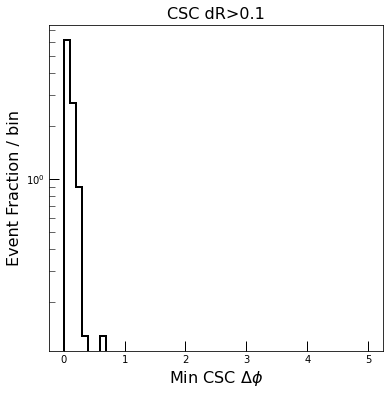

In [43]:
fig, offPlot = plt.subplots(
       nrows=1
  )
fig.set_figheight(6)
mcHist = offPlot.hist(minDphi,density=True,label='CSC dR>0.1',histtype='step',bins=binsx,linewidth=2, color='black')
plt.yscale("log")
plt.title('CSC dR>0.1',fontsize=16)
plt.xlabel("Min CSC $\Delta\phi$",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
tx = predPlot.text(0.45, 2, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(0.57, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [44]:
binsx = [5*binx/50. for binx in range(51)]
cscAdjMC = scoredMC.copy()
minDr = [10] * cscAdjMC.shape[0]
secondMinDr = [10] * cscAdjMC.shape[0]
minDeta = [10] * cscAdjMC.shape[0]
minDphi = [10] * cscAdjMC.shape[0]

for station in range(0,4):
    for idx, entry in enumerate(cscAdjMC['cscDEtabyStation_'+str(station)]):
        if entry<minDeta[idx]:
            minDeta[idx] = entry
    for idx, entry in enumerate(cscAdjMC['cscDPhibyStation_'+str(station)]):
        if abs(entry)<abs(minDphi[idx]):
            minDphi[idx] = entry    
    for idx, entry in enumerate(cscAdjMC['cscDRbyStation_'+str(station)]):
        if entry>0 and entry<minDr[idx]:
            secondMinDr[idx] = minDr[idx]
            minDr[idx] = entry
        elif entry>0 and entry<secondMinDr[idx]:
            secondMinDr[idx] = entry

cscAdjMC['cscMinDeta'] = minDeta
cscAdjMC['cscMinDphi'] = minDphi
cscAdjMC['newCSCminDr'] = minDr
cscAdjMC['secondCSCminDr'] = secondMinDr

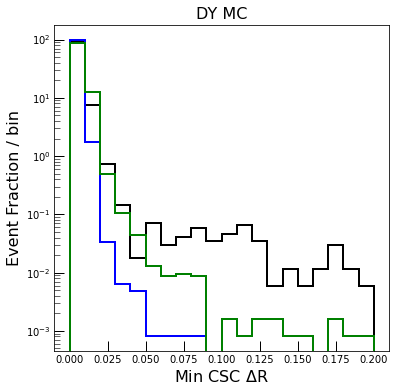

In [45]:
fig, offPlot = plt.subplots(
       nrows=1
  )
fig.set_figheight(6)
binsx = [binx/100. for binx in range(21)]
offHist = offPlot.hist(offPeakData['cscDR'],density=True,label='Off Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
newMcHist = offPlot.hist(cscAdjMC['newCSCminDr'],density=True,label='Recalc Min DR',histtype='step',bins=offHist[1],linewidth=2, color='blue')
secondMcHist = offPlot.hist(cscAdjMC['secondCSCminDr'],density=True,label='Second Min DR',histtype='step',bins=offHist[1],linewidth=2, color='green')
plt.yscale("log")
plt.title('DY MC',fontsize=16)
plt.xlabel("Min CSC $\Delta$R",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
predPlot.yaxis.set_ticks_position('both')
predPlot.xaxis.set_ticks_position('both')
leg=predPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
tx = predPlot.text(0.45, 2, "CMS", size="x-large",weight='bold')
tx2 = predPlot.text(0.57, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [46]:
def calcAvgDPhi(dataframe):
    dphis = [-10] * dataframe.shape[0]
    counts = [1] * dataframe.shape[0]

    for station in range(1,4):
        for idx, entry in enumerate(dataframe['cscDPhibyStation_'+str(station)]):
            if entry > -0.9:
                if dphis[idx] < -9:
                    dphis[idx] = entry
                else:
                    dphis[idx] = dphis[idx]+entry
                    counts[idx] = counts[idx] + 1
    for idx, entry in enumerate(dphis):
        dphis[idx] = dphis[idx]/counts[idx]
        
    return dphis

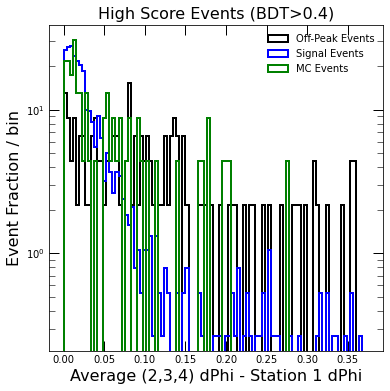

In [47]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [0.3*binx/80 for binx in range(101)]
#binsx = [0.5*binx/20 for binx in range(101)]
minHighData = [10] * highScoreOffPeak.shape[0]
minHighSig = [10] * highScoreSigEvents.shape[0]
minHighMC = [10] * highScoreMC.shape[0]
for station in range(1,4):
    for idx, entry in enumerate(highScoreOffPeak['cscDPhibyStation_'+str(station)]):
        if abs(entry-highScoreOffPeak['cscDPhibyStation_0'].iloc[idx])<minHighData[idx]:
            minHighData[idx] = abs(entry-highScoreOffPeak['cscDPhibyStation_0'].iloc[idx])
    for idx, entry in enumerate(highScoreSigEvents['cscDPhibyStation_'+str(station)]):
        if abs(entry-highScoreSigEvents['cscDPhibyStation_0'].iloc[idx])<minHighSig[idx]:
            minHighSig[idx] = abs(entry-highScoreSigEvents['cscDPhibyStation_0'].iloc[idx])
    for idx, entry in enumerate(highScoreMC['cscDPhibyStation_'+str(station)]):
        if abs(entry-highScoreMC['cscDPhibyStation_0'].iloc[idx])<minHighMC[idx]:
            minHighMC[idx] = abs(entry-highScoreMC['cscDPhibyStation_0'].iloc[idx])

avgData = calcAvgDPhi(highScoreOffPeak)
avgSig = calcAvgDPhi(highScoreSigEvents)
avgMC = calcAvgDPhi(highScoreMC)
            
highScoreHist = offPlot.hist(abs(avgData-highScoreOffPeak['cscDPhibyStation_0']),density=True,label='Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
regOffHist = offPlot.hist(abs(avgSig-highScoreSigEvents['cscDPhibyStation_0']),density=True,label='Signal Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')        
mcHist = offPlot.hist(abs(avgMC-highScoreMC['cscDPhibyStation_0']),density=True,label='MC Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')     

plt.yscale("log")
plt.title('High Score Events (BDT>0.4)',fontsize=16)
plt.xlabel("Average (2,3,4) dPhi - Station 1 dPhi",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

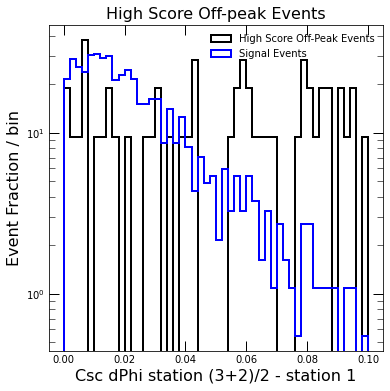

In [48]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [0.1*binx/50 for binx in range(51)]
noMissOneOff = highScoreOffPeak[highScoreOffPeak['cscDRbyStation_0']>-0.9]
noMissOneSig = highScoreSigEvents[highScoreSigEvents['cscDRbyStation_0']>-0.9]
noMissOneMC = highScoreMC[highScoreMC['cscDRbyStation_0']>-0.9]
highScoreHist = offPlot.hist(abs((noMissOneOff['cscDPhibyStation_2']+noMissOneOff['cscDPhibyStation_1'])/2.-noMissOneOff['cscDPhibyStation_0']),density=True,label='High Score Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
regOffHist = offPlot.hist(abs((noMissOneSig['cscDPhibyStation_2']+noMissOneSig['cscDPhibyStation_1'])/2.-noMissOneSig['cscDPhibyStation_0']),density=True,label='Signal Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')        
#mcHist = offPlot.hist(abs((noMissOneMC['cscDPhibyStation_2']+noMissOneMC['cscDPhibyStation_1'])/2.-noMissOneMC['cscDPhibyStation_0']),density=True,label='MC Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')     

plt.yscale("log")
plt.title('High Score Off-peak Events',fontsize=16)
plt.xlabel("Csc dPhi station (3+2)/2 - station 1",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

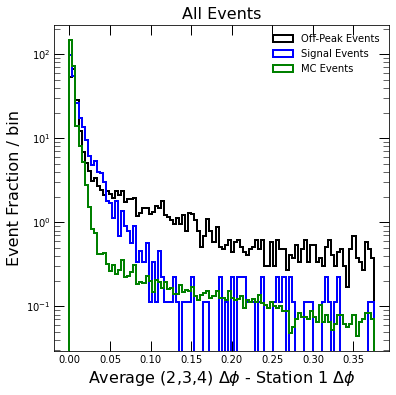

In [49]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
#binsx = [0.5*binx/20 for binx in range(101)]
binsx = [0.3*binx/80 for binx in range(101)]
minData = [-10] * offPeakData.shape[0]
minSig = [-10] * sigEvents.shape[0]
minMC = [-10] * mcEvents.shape[0]
minDataCounts = [1] * offPeakData.shape[0]
minSigCounts = [1] * sigEvents.shape[0]
minMCCounts = [1] * mcEvents.shape[0]

for station in range(1,4):
    for idx, entry in enumerate(offPeakData['cscDPhibyStation_'+str(station)]):
        if entry > -0.9:
            if minData[idx] < -9:
                minData[idx] = entry
            else:
                minData[idx] = minData[idx]+entry
                minDataCounts[idx] = minDataCounts[idx] + 1
    for idx, entry in enumerate(sigEvents['cscDPhibyStation_'+str(station)]):
        if entry > -0.9:
            if minSig[idx] < -9:
                minSig[idx] = entry
            else:
                minSig[idx] = minSig[idx]+entry
                minSigCounts[idx] = minSigCounts[idx] + 1        
    for idx, entry in enumerate(mcEvents['cscDPhibyStation_'+str(station)]):
        if entry > -0.9:
            if minMC[idx] < -9:
                minMC[idx] = entry
            else:
                minMC[idx] = minMC[idx]+entry
                minMCCounts[idx] = minMCCounts[idx] + 1           

for idx, entry in enumerate(minData):
    minData[idx]=minData[idx]/minDataCounts[idx]
for idx, entry in enumerate(minSig):
    minSig[idx]=minSig[idx]/minSigCounts[idx]
for idx, entry in enumerate(minMC):
    minMC[idx]=minMC[idx]/minMCCounts[idx]
#highScoreHist = offPlot.hist(minData,density=True,label='Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
#regOffHist = offPlot.hist(minSig,density=True,label='Signal Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')        
#mcHist = offPlot.hist(minMC,density=True,label='MC Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')     
highScoreHist = offPlot.hist(minData-offPeakData['cscDPhibyStation_0'],density=True,label='Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')
regOffHist = offPlot.hist(sigEvents['cscDPhibyStation_1']-sigEvents['cscDPhibyStation_0'],density=True,label='Signal Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='blue')        
mcHist = offPlot.hist(mcEvents['cscDPhibyStation_1']-mcEvents['cscDPhibyStation_0'],density=True,label='MC Events',histtype='step',bins=highScoreHist[1],linewidth=2, color='green')

plt.yscale("log")
plt.title('All Events',fontsize=16)
plt.xlabel("Average (2,3,4) $\Delta\phi$ - Station 1 $\Delta\phi$",fontsize=16)
plt.ylabel('Event Fraction / bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

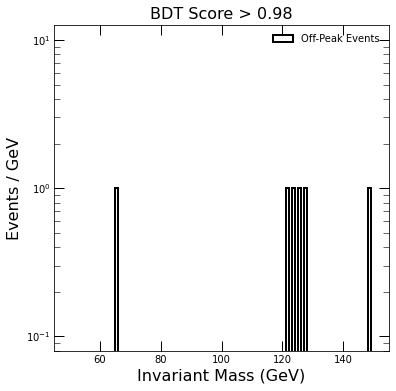

In [50]:
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
#binsx = [0.5*binx/20 for binx in range(101)]
binsx = [binx+50 for binx in range(101)]

highScoreLowStdOff = lowStdOff[lowStdOff['BDTScore']>0.98]
highScoreHist = offPlot.hist(highScoreLowStdOff['invMass'],density=False,label='Off-Peak Events',histtype='step',bins=binsx,linewidth=2, color='black')

plt.yscale("log")
plt.title('BDT Score > 0.98',fontsize=16)
plt.xlabel("Invariant Mass (GeV)",fontsize=16)
plt.ylabel('Events / GeV',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [51]:
offPeakVector = []
for idx, entry in enumerate(highScoreLowStdOff['invMass']):
    offPeakVector.append(entry)
#pickle.dump(offPeakVector, open("offPeakEvents.pkl", "w"))
with open('offPeakEvents.pkl','wb') as f:
    pickle.dump(offPeakVector, f, protocol=2)
print(offPeakVector)

[123.88861083984375, 127.89080810546875, 121.2575454711914, 125.12952423095703, 148.14337158203125, 65.61064147949219]


In [52]:
print(lowStdMC[lowStdMC['BDTScore']<0.7].shape[0]*398*58.6*1000/961690*971381/1.4/(10**7))
print(lowStdData.shape[0])

193890.9964960358
262896


In [53]:
print(lowScoreMC[lowScoreMC['BDTScore']<0.7].shape[0]*398*58.6*1000/961690*971381/1.4/(10**7))
print(lowScoreData.shape[0])

210078.58771930018
404409


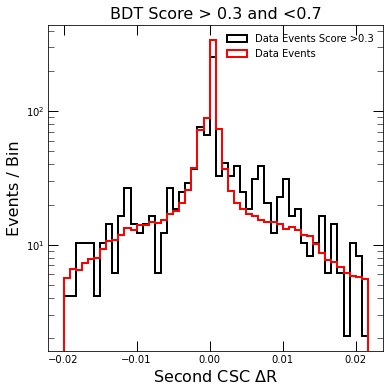

In [54]:
medScoreData = lowScoreData[lowScoreData['BDTScore']>0.3]

fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [binx/1200-0.02 for binx in range(51)]
#binsx = [binx+50 for binx in range(101)]

medScoreSecHist = offPlot.hist(medScoreData['seccscDPhibyStation_3']-medScoreData['cscDPhibyStation_3'],density=True,label='Data Events Score >0.3',histtype='step',bins=binsx,linewidth=2, color='black')
lowScoreSecHist = offPlot.hist(lowScoreData['seccscDPhibyStation_3']-lowScoreData['cscDPhibyStation_3'],density=True,label='Data Events',histtype='step',bins=binsx,linewidth=2, color='red')

plt.yscale("log")
plt.title('BDT Score > 0.3 and <0.7',fontsize=16)
plt.xlabel("Second CSC $\Delta$R",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')
    #plt.xlim([0.,1.])
#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

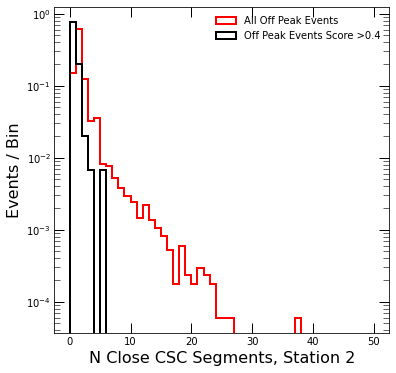

In [55]:
highScoreOffPeak = offPeakData[offPeakData['BDTScore']>0.4].copy()
fig, offPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
binsx = [binx for binx in range(51)]
#binsx = [binx+50 for binx in range(101)]

lowScoreOffHist = offPlot.hist(offPeakData['nCloseHitsStation_2'],density=True,label='All Off Peak Events',histtype='step',bins=binsx,linewidth=2, color='red')
highScoreOffHist = offPlot.hist(highScoreOffPeak['nCloseHitsStation_2'],density=True,label='Off Peak Events Score >0.4',histtype='step',bins=lowScoreOffHist[1],linewidth=2, color='black')


plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("N Close CSC Segments, Station 2",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
offPlot.yaxis.set_ticks_position('both')
offPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')

#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

In [56]:
highScoreOffPeak[highScoreOffPeak['nCloseHitsStation_3']>5].shape[0]

0

In [57]:
idSF = mcFile["demo"]["allEvents"]["IDSF"].to_numpy()
idSFup = mcFile["demo"]["allEvents"]["IDSFup"].to_numpy()
idSFdown = mcFile["demo"]["allEvents"]["IDSFdown"].to_numpy()

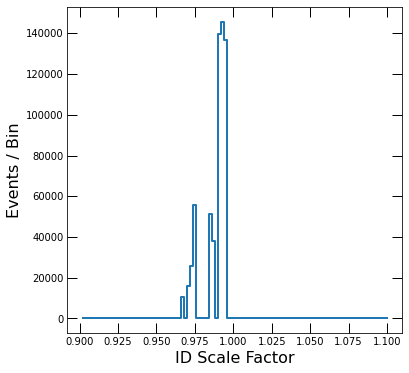

In [58]:
fig, idSFPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)
#binsx = [binx for binx in range(51)]
#binsx = [binx+50 for binx in range(101)]

nomHist = idSFPlot.step(idSF[1][1:],idSF[0],label='Nominal',where='post',linewidth=2)
#counts, edges, fill=True)
#highScoreOffHist = offPlot.hist(highScoreOffPeak['nCloseHitsStation_2'],density=True,label='Off Peak Events Score >0.4',histtype='step',bins=lowScoreOffHist[1],linewidth=2, color='black')
 #ratio.step(bins[:-1],ratioHist,where='post',color='black')

#plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("ID Scale Factor",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
idSFPlot.yaxis.set_ticks_position('both')
idSFPlot.xaxis.set_ticks_position('both')
leg=offPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = offPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = offPlot.text(0.08, 2, "Internal", size="x-large",style='italic')

#   plt.savefig("plots/offPeakEcalIso.pdf")
plt.show()

10841
13659


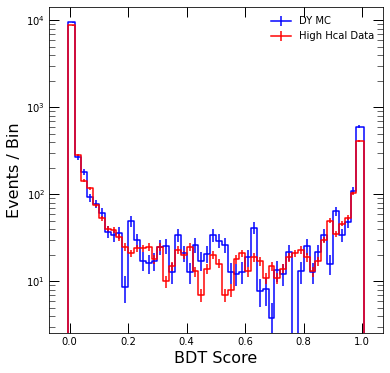

In [59]:
passCutHighHcalMC = scoredHighHcalMC[scoredHighHcalMC['closeHits']>1]
passCutHighHcalData = scoredHighHcalData[scoredHighHcalData['closeHits']>1]
passCutSameSignHighHcal = scoredSameSignHighHcal[scoredSameSignHighHcal['closeHits']>1]
print(passCutHighHcalData.shape[0])
print(scoredHighHcalData.shape[0])
fig, highHcalPlot = plt.subplots(
        nrows=1
    )

binsx = [binx/50. for binx in range(51)]
highHcalLumi = 59.74
sameSignLumi = 58.6
dyXsec = 398
#dyScale = highHcalLumi*dyXsec*1000/3860000
dyScale=4.4
#print(dyScale)
#passCutHighHcalMC['EventWeight']
highHcalMCCounts = np.histogram(passCutHighHcalMC['BDTScore'],density=False,bins=binsx, weights=passCutHighHcalMC['EventWeight']*dyScale)
sameSignScale = highHcalLumi/sameSignLumi
sameSignHighHcalCounts = np.histogram(passCutSameSignHighHcal['BDTScore'],density=False,bins=binsx, weights=passCutSameSignHighHcal['EventWeight']*sameSignScale)
highHcalDataCounts = np.histogram(passCutHighHcalData['BDTScore'],density=False,bins=binsx)

bin_centers = (highHcalMCCounts[1][:-1] + highHcalMCCounts[1][1:])/2.                                                       
                                                     
np_counts_mc = np.asarray(highHcalMCCounts[0])
  #counts_bkg_sqrt = np.sqrt(np_counts_bkg)/(testBkgWeights.sum()*0.04)

counts_mc_sqrt = []
totalCounts = 0
for counts in np_counts_mc:
    error = np.sqrt(counts)
    counts_mc_sqrt.append(error)
    totalCounts = totalCounts + counts

np_counts_data = np.asarray(highHcalDataCounts[0])
totalData = scoredHighHcalData['BDTScore'].shape[0]
counts_data_sqrt = []
for counts in np_counts_data:
    error = np.sqrt(counts*4.4)/4.4
    counts_data_sqrt.append(error)
    
np_counts_sameSign = np.asarray(sameSignHighHcalCounts[0])
counts_sameSign_sqrt = []
for counts in np_counts_sameSign:
    error = np.sqrt(counts)
    counts_sameSign_sqrt.append(error)  
    
    
fig.set_figheight(6)

appMCCounts = np.append(highHcalMCCounts[0],0)
appMCCounts = np.insert(appMCCounts,0,0)
counts_mc_sqrt.append(0)
counts_mc_sqrt.insert(0,0)
appDataCounts = np.append(highHcalDataCounts[0],0)
appDataCounts = np.insert(appDataCounts,0,0)
counts_data_sqrt.append(0)
counts_data_sqrt.insert(0,0)
appSameSignCounts = np.append(sameSignHighHcalCounts[0],0)
appSameSignCounts = np.insert(appSameSignCounts,0,0)
counts_sameSign_sqrt.append(0)
counts_sameSign_sqrt.insert(0,0)
bin_centers = np.append(bin_centers,1.02)
bin_centers = np.insert(bin_centers,0,-0.02)

plt.errorbar(bin_centers, appMCCounts, yerr=counts_mc_sqrt,  color='Blue',
               label='DY MC',drawstyle = 'steps-mid')
plt.errorbar(bin_centers, appDataCounts, yerr=counts_data_sqrt,  color='Red',
               label='High Hcal Data',drawstyle = 'steps-mid')
#plt.errorbar(bin_centers, appSameSignCounts, yerr=counts_sameSign_sqrt,  color='Green',
#               label='mu+x',drawstyle = 'steps-mid')
#plt.errorbar(bin_centers, counts_data, yerr=counts_data_sqrt, fmt='o', ecolor='Red',
#               mfc='Red',mec='Red',label='Data')


plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("BDT Score",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
highHcalPlot.yaxis.set_ticks_position('both')
highHcalPlot.xaxis.set_ticks_position('both')
leg=highHcalPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
#tx = highHcalPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = highHcalPlot.text(0.08, 2, "Internal", size="x-large",style='italic')

plt.savefig("plots/highHcalValid.pdf")
plt.show()

In [60]:
print(sum(passCutHighHcalMC[passCutHighHcalMC['BDTScore']>0.98]['EventWeight'])/sum(passCutHighHcalMC['EventWeight']))
print(passCutHighHcalData[passCutHighHcalData['BDTScore']>0.98].shape[0]/passCutHighHcalData.shape[0])

0.05054408308361779
0.03754266211604096


In [61]:
def getcscStationWeight(sfhist,cscSegmentDR):
    weights = []
    for cscIndex, cscDR in enumerate(cscSegmentDR):
      if cscDR > 2:
        cscDR = -1      
      for idx, value in enumerate(sfhist.axis().edges()):
        if(cscDR<value):
            cscWeight = sfhist.values()[idx-1]
            break
      weights.append(cscWeight)
    return np.array(weights)

In [62]:
cscWeights = []
stationThresh = [0.1,0.1,0.1,0.1]
for station in range(4):
    MCcounts = [0,0,0]
    for idx, entry in enumerate(passCutHighHcalMC['cscDRbyStation_'+str(station)]):
        if entry>0 and entry < stationThresh[station]:
            MCcounts[0] = MCcounts[0]+passCutHighHcalMC['EventWeight'].iloc[idx]
        elif entry>0 and entry < 1.:
            MCcounts[1] = MCcounts[1]+passCutHighHcalMC['EventWeight'].iloc[idx]
        else:
            MCcounts[2] = MCcounts[2]+passCutHighHcalMC['EventWeight'].iloc[idx]
    dataCounts = [0,0,0]
    for idx, entry in enumerate(passCutHighHcalData['cscDRbyStation_'+str(station)]):
        if entry>0 and entry < stationThresh[station]:
            dataCounts[0] = dataCounts[0]+1
        elif entry>0 and entry < 1.:
            dataCounts[1] = dataCounts[1]+1
        else:
            dataCounts[2] = dataCounts[2]+1
    totMC = sum(MCcounts)
    MCcounts[0] = MCcounts[0]/totMC
    MCcounts[1] = MCcounts[1]/totMC
    MCcounts[2] = MCcounts[2]/totMC
    totData = sum(dataCounts)
    dataCounts[0] = dataCounts[0]/totData
    dataCounts[1] = dataCounts[1]/totData
    dataCounts[2] = dataCounts[2]/totData
    newSFs = [1,1,1]
    if dataCounts[0]>0 and MCcounts[0]>0:
        newSFs[0] = dataCounts[0]/MCcounts[0]
    if dataCounts[1]>0 and MCcounts[1]>0:
        newSFs[1] = dataCounts[1]/MCcounts[1]
    if dataCounts[2]>0 and MCcounts[2]>0:
        newSFs[2] = dataCounts[2]/MCcounts[2]
    cscWeights.append(newSFs)
print(cscWeights)

[[0.9981551517387695, 1, 1], [0.9400567893368462, 1.2678371596084979, 2.1256960836561696], [0.9638011405041108, 1.5029775469664297, 1.661187710403724], [0.9898578624043505, 0.8214531151183043, 1.1209473625803092]]


In [63]:
chiWeights = []
binsx = [10*binx/50. for binx in range(31)]
binsx = binsx+[10]
chiCountsMC = np.histogram(passCutHighHcalMC['staChi'],density=True,bins=binsx, weights=passCutHighHcalMC['EventWeight'])  
chiCountsData = np.histogram(passCutHighHcalData['staChi'],density=True,bins=chiCountsMC[1])  
chiWeights = chiCountsData[0]/chiCountsMC[0]
print(chiWeights)


[0.42739358 0.70884346 0.76870581 0.92129207 0.95552679 1.0892938
 1.10438688 1.06050315 1.00166166 1.10057286 1.27106542 1.0901211
 1.16247799 0.80500564 1.24053819 1.61777381 1.34663781 1.53754605
 1.24850857 1.2997589  1.27568108 2.43752372 0.95465117 0.89495012
 0.86235    7.34804462 4.51850203 1.68584141 2.24294595 0.97392655
 2.07475054]


In [66]:
#cscSfHists = []
#for depth in range(4):
#    cscSfHists.append(uproot.open("/local/cms/user/revering/dphoton/slc7/CMSSW_10_6_17_patch1/src/DarkPhoton/MuAnalyzer/jupyterstuff/cscStationSFs.root:cscScaleFactor_station"+str(depth)))
#cscReweight0=getcscStationWeight(cscSfHists[0],passCutHighHcalMC['cscDRbyStation_'+str(0)])
#cscReweight1=getcscStationWeight(cscSfHists[1],passCutHighHcalMC['cscDRbyStation_'+str(1)])
#cscReweight2=getcscStationWeight(cscSfHists[2],passCutHighHcalMC['cscDRbyStation_'+str(2)])
#cscReweight3=getcscStationWeight(cscSfHists[3],passCutHighHcalMC['cscDRbyStation_'+str(3)])
#testWeight = []
#for idx, entry in enumerate(passCutHighHcalMC['cscDRbyStation_'+str(1)]):
#    if entry<0:
#        testWeight.append(3)
#    else:
#        testWeight.append(1)
#for idx, entry in enumerate(passCutHighHcalMC['cscDRbyStation_'+str(2)]):
#    if entry<0:
#        testWeight[idx] = testWeight[idx]*1.5
cscReweights = [[],[],[],[]]
for station in range(4):
    for idx, entry in enumerate(passCutHighHcalMC['cscDRbyStation_'+str(station)]):
        if entry>0 and entry < stationThresh[station]:
            cscReweights[station].append(cscWeights[station][0])
        elif entry>0  and entry<1.:
            cscReweights[station].append(cscWeights[station][1])
        else:
            cscReweights[station].append(cscWeights[station][2])

chiReWeights = []
for idx, entry in enumerate(passCutHighHcalMC['staChi']):
    chiReWeights.append(float(1))
    for idx2, binedge in enumerate(chiCountsMC[1][1:]):
        if entry<binedge:
            chiReWeights[idx] = float(float(chiReWeights[idx])*float(chiWeights[idx2]))
            break

print(passCutHighHcalMC['staChi'].shape[0])
print(len(chiReWeights))
#newWeights = chiReWeights

newWeights=passCutHighHcalMC['EventWeight']*cscReweights[0]*cscReweights[1]*cscReweights[2]*cscReweights[3]
#newWeights=passCutHighHcalMC['EventWeight']*cscReweight0*cscReweight1*cscReweight2*cscReweight3

2756
2756


[9.23578177e+03 2.72151626e+02 1.87718164e+02 8.70489171e+01
 6.92495284e+01 5.21802479e+01 3.72657574e+01 3.54237556e+01
 3.37692539e+01 1.29194738e+01 5.30835437e+01 2.76038603e+01
 1.98925662e+01 1.40877399e+01 1.79356004e+01 2.21590782e+01
 2.71143389e+01 1.87238449e+01 3.50168380e+01 1.81256807e+01
 1.11312293e+01 3.12570134e+01 1.52788758e+01 2.21662396e+01
 4.82242595e+01 2.99592219e+01 2.76769534e+01 1.10812237e+01
 1.06565726e+01 1.61574877e+01 1.89581080e+01 4.59624317e+01
 6.23184839e+00 6.69207039e+00 2.85474541e+00 1.82126032e+01
 1.28479326e+01 2.19423617e+01 0.00000000e+00 1.44120524e+01
 2.17301453e+01 1.16219614e+01 2.36609683e+01 3.51322569e+01
 1.33219126e+01 7.19279131e+01 3.30399861e+01 4.26815887e+01
 1.04682382e+02 5.55665955e+02]
[8739  285  144  117   75   53   40   39   32   25   21   24   24   25
   18   25   10   15   23   20   25   13    7   14   20   16    7    8
   18   21   13   19   17   11   15   11   14   19   21   23   19   13
   17   30   50   35   

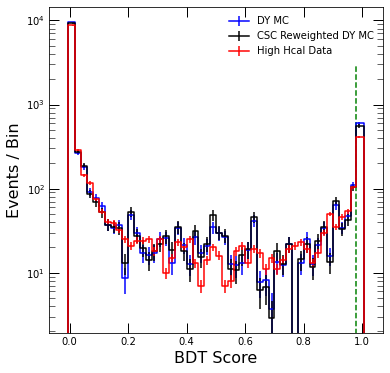

In [84]:
reweightCounts = np.histogram(passCutHighHcalMC['BDTScore'],density=False,bins=highHcalMCCounts[1], weights=passCutHighHcalMC['EventWeight']*dyScale*newWeights)                                                 
                                                     
np_counts_reweight = np.asarray(reweightCounts[0])
  #counts_bkg_sqrt = np.sqrt(np_counts_bkg)/(testBkgWeights.sum()*0.04)

counts_reweight_sqrt = []
for counts in np_counts_reweight:
    error = np.sqrt(counts)
    counts_reweight_sqrt.append(error)

fig, highHcalPlot = plt.subplots(
        nrows=1
    )
fig.set_figheight(6)

appReweightCounts = np.append(reweightCounts[0],0)
appReweightCounts = np.insert(appReweightCounts,0,0)
counts_reweight_sqrt.append(0)
counts_reweight_sqrt.insert(0,0)

print(reweightCounts[0])
print(highHcalDataCounts[0])
print(counts_mc_sqrt)
plt.errorbar(bin_centers, appMCCounts, yerr=counts_mc_sqrt,  color='Blue',
               label='DY MC',drawstyle = 'steps-mid')
plt.errorbar(bin_centers, appReweightCounts, yerr=counts_reweight_sqrt,  color='Black',
               label='CSC Reweighted DY MC',drawstyle = 'steps-mid')
#plt.errorbar(bin_centers, appSameSignCounts, yerr=counts_sameSign_sqrt,  color='Green',
#               label='mu+x',drawstyle = 'steps-mid')
plt.errorbar(bin_centers, appDataCounts, yerr=counts_data_sqrt,  color='Red',
               label='High Hcal Data',drawstyle = 'steps-mid')


plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
plt.xlabel("BDT Score",fontsize=16)
plt.ylabel('Events / Bin',fontsize=16)
plt.tick_params(direction='in', length=10, width=1)
plt.tick_params(which='minor', direction='in',length=6)
highHcalPlot.yaxis.set_ticks_position('both')
highHcalPlot.xaxis.set_ticks_position('both')
leg=highHcalPlot.legend(loc='upper right')
leg.get_frame().set_alpha(0)
x_points = [0.98,0.98]
y_points = [0., 3000]
plt.plot(x_points, y_points, 'g',linestyle='dashed')
#tx = highHcalPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = highHcalPlot.text(0.08, 2, "Internal", size="x-large",style='italic')

plt.savefig("plots/highHcal_cscReweight.pdf")
plt.show()

In [ ]:
def prepInputFile(inputFile,feats,nonBDTfeats,BDTs):
    allFeats = feats+nonBDTfeats
    inputData = inputFile["demo"]["partialDisappear"]["sigVariables"]
    input_arr = inputData.arrays(allFeats,library="pd")
    inputDataEvents = input_arr[~edgeCond(input_arr)&(input_arr['standaloneDEoverE']<-0.6)].copy()
    inputDataEvents['staPhi']=inputDataEvents['staPhi']*inputDataEvents['probeCharge']
    inputDataEvents = setZeroes(inputDataEvents)
    BDTInputs = inputDataEvents.copy()
    BDTInputs.drop(nonBDTfeats,inplace=True,axis=1)
    input_preds = BDTs[0][0].predict(BDTInputs)
    inputData = inputDataEvents.copy()
    inputData['BDTScore'] = input_preds
    return inputData

In [ ]:
sigFiles = [uproot.open(basePath+"ZmmDBrem_map"+mass+"_fixBiasing.root") for mass in ["0p2","0p4","0p6","0p8","1p0"]]
sigArrays = []
for file in sigFiles:
    sigArrays.append(prepInputFile(file, bdtfeatures, nonBDTfeats, BDTs))

In [ ]:
highPerformingFeats = ['cscDRbyStation_1','HEDepth_4','staChi','eta','staPhi']
sigLabels = ['mA\' = 0.2 GeV','mA\' = 0.4 GeV','mA\' = 0.6 GeV','mA\' = 0.8 GeV','mA\' = 1.0 GeV']
axisLabels = ['$\Delta$R to nearest CSC Hit, Station 2','HCAL Energy in Depth 4 (GeV)', 'Standalone Muon Reduced $\chi^{2}$','Probe Track $\eta$','Standalone Muon $\phi$*Probe Track Charge']

colors = ['red','green','black','orange','green']
for i, feat in enumerate(highPerformingFeats):
    fig, highHcalPlot = plt.subplots(
        nrows=1
    )
    fig.set_figheight(6)
    binsx = 10

    DYCounts = np.histogram(lowStdMC[feat],density=True,bins=50, weights=lowStdMC['EventWeight'])

    bin_centers = (DYCounts[1][:-1] + DYCounts[1][1:])/2.                                                       
                                                  
    np_counts_dy = np.asarray(DYCounts[0])
    counts_DY_sqrt = []
    totalDY = sum(lowStdMC['EventWeight'])
    binWidth = bin_centers[1]-bin_centers[0]
    for counts in np_counts_dy:
        error = np.sqrt(counts*totalDY*binWidth)/totalDY/binWidth
        counts_DY_sqrt.append(error)
    
    appDYCounts = np.append(DYCounts[0],0)
    appDYCounts = np.insert(appDYCounts,0,0)
    counts_DY_sqrt.append(0)
    counts_DY_sqrt.insert(0,0)
    bin_centers = np.append(bin_centers,bin_centers[-1]+binWidth)
    bin_centers = np.insert(bin_centers,0,bin_centers[0]-binWidth)

    plt.errorbar(bin_centers, appDYCounts, yerr=counts_DY_sqrt,  color='Blue',
                   label='DY MC',drawstyle = 'steps-mid')
    for idx, massArr in enumerate(sigArrays):
        if idx == 1 or idx ==3:
            continue
        SigCounts = np.histogram(massArr[feat],density=True,bins=DYCounts[1], weights=massArr['EventWeight'])
                                                                            
        np_counts_sig = np.asarray(SigCounts[0])
        counts_sig_sqrt = []
        totalCount = sum(massArr['EventWeight'])
        for counts in np_counts_sig:
            error = np.sqrt(counts*totalCount*binWidth)/totalCount/binWidth
            counts_sig_sqrt.append(error)
    

        appSigCounts = np.append(SigCounts[0],0)
        appSigCounts = np.insert(appSigCounts,0,0)
        counts_sig_sqrt.append(0)
        counts_sig_sqrt.insert(0,0)
        plt.errorbar(bin_centers, appSigCounts, yerr=counts_sig_sqrt,  color=colors[idx],
               label=sigLabels[idx],drawstyle = 'steps-mid')
#plt.errorbar(bin_centers, appSameSignCounts, yerr=counts_sameSign_sqrt,  color='Green',
#               label='mu+x',drawstyle = 'steps-mid')
#plt.errorbar(bin_centers, counts_data, yerr=counts_data_sqrt, fmt='o', ecolor='Red',
#               mfc='Red',mec='Red',label='Data')


    plt.yscale("log")
#plt.title('BDT Score > 0.3 and <0.7',fontsize=16
    plt.xlabel(axisLabels[i],fontsize=16)
    if feat=="HEDepth_4":
        plt.ylabel('Events / '+str(round(binWidth, 2))+' GeV')
    else:
        plt.ylabel('Events / Bin',fontsize=16)
    
    plt.tick_params(direction='in', length=10, width=1)
    plt.tick_params(which='minor', direction='in',length=6)
    highHcalPlot.yaxis.set_ticks_position('both')
    highHcalPlot.xaxis.set_ticks_position('both')
    leg=highHcalPlot.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
#tx = highHcalPlot.text(0.06, 2, "CMS", size="x-large",weight='bold')
#tx2 = highHcalPlot.text(0.08, 2, "Internal", size="x-large",style='italic')

    plt.savefig("plots/bdtInputFeats"+feat+".pdf")
    plt.show()

In [ ]:
featLabels =  ["Probe Track p$_t$ (GeV)",
               "Probe Track $\eta$",
               "Probe Track $\phi$",
               "$\Delta$R from probe track to nearest standalone muon",
               "$\Delta\phi$ from probe track to standalone muon * track charge",
               "Standalone muon energy (GeV)",
               "Standalone muon reduced $\chi^2$",
               "$\Delta$R to nearest CSC segment",
               "HCAL Energy, Depth 1 (GeV)",
               "HCAL Energy, Depth 2 (GeV)",
               "HCAL Energy, Depth 3 (GeV)",
               "HCAL Energy, Depth 4 (GeV)",
               "HCAL Energy, Depth 5 (GeV)",
               "HCAL Energy, Depth 6 (GeV)",
               "HCAL Energy, Depth 7 (GeV)",
               "Probe Track Charge",
               "(Standalone muon E - Probe Track E)/Probe Energy",
               "$\Delta$R to nearest CSC Segment in station 1",
               "$\Delta$R to nearest CSC Segment in station 2",
               "$\Delta$R to nearest CSC Segment in station 3",
               "$\Delta$R to nearest CSC Segment in station 4"]
for idx, feature in enumerate(bdtfeatures):
    fig, (absolute, ratio) = plt.subplots(
        nrows=2,
        sharex = 'col', # have the columns share the x axis
        gridspec_kw = dict(
            hspace = 0.0, # shrink height space between the two figs
            height_ratios = [2,1]
        )
    )
    fig.set_figheight(6)
    if feature=='staChi':
        binsx = [10*binx/50. for binx in range(51)]
    elif feature=='cscDR':
        binsx = [binx/100. for binx in range(21)]
    else:
        binsx = 50
    if 'HEDepth' in feature:
        binsx = [10*binx/25. for binx in range(26)]
    lowScoreHist = absolute.hist(passCutHighHcalData[feature],density=True,label='Data',histtype='step',bins=binsx,linewidth=2, color='black', weights=passCutHighHcalData['EventWeight'])
    lowScoreMCHist = absolute.hist(passCutHighHcalMC[feature],bins=lowScoreHist[1],density=True,label='DY MC',histtype='step',linewidth=2, color='blue', weights=newWeights)
    #offPeakHist = absolute.hist(lowStdOff[feature],density=True,label='High Score Off-Peak Events',histtype='step',bins=lowScoreHist[1],linewidth=2, color='red', weights=lowStdOff['EventWeight'])
    #sigHist = absolute.hist(lowStdSig[feature],bins=lowScoreHist[1],density=True,label='mAp 0p2 GeV',histtype='step',linewidth=2, color='green', weights=lowStdSig['EventWeight'])
    absolute.set_yscale('log')
    absolute.set_ylabel('Event Fraction / bin',fontsize=16)
    absolute.legend()
    ratioHist = lowScoreHist[0]/lowScoreMCHist[0]
    ratio.plot(lowScoreHist[1][:-1],ratioHist,color='black',marker='s',linestyle='none',markersize=5)
    ratio.set_ylabel('Data/MC',fontsize=16)

    leg=absolute.legend(loc='upper right')
    leg.get_frame().set_alpha(0)
    if feature=='staChi':
        ratio.set_xlim([0, 10])
    if feature=='eta':
        absolute.set_ylim(0.06, 9)
    if feature=='standaloneDEoverE':
        absolute.set_ylim(0.002,200)
    yrange = absolute.get_ylim()
    xrange = absolute.get_xlim()
    tx = absolute.text(xrange[0]+(xrange[1]-xrange[0])*0.6,yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),  "CMS", size="x-large",weight='bold')
    tx2 = absolute.text(xrange[0]+(xrange[1]-xrange[0])*0.72, yrange[0]*10.**((math.log(yrange[1],10)-math.log(yrange[0],10))*0.75),"Preliminary", size="x-large",style='italic')
    absolute.tick_params(direction='in', length=10, width=1)
    absolute.tick_params(which='minor', direction='in',length=6)
    absolute.yaxis.set_ticks_position('both')
    absolute.set_title('BDT Score < 0.7',fontsize=16)
    #absolute.set_ylim([0.0005,2.2])
    ratio.set_xlabel(featLabels[idx],fontsize=16)
    ratio.tick_params(direction='in', length=8, width=1)
    ratio.yaxis.set_ticks_position('both')
    ratio.xaxis.set_ticks_position('both')

    #ratio.set_ylim([0.7,1.3])
    x_points = ratio.get_xlim()
    y_points = [1, 1]
    ratio.plot(x_points, y_points, 'black',linestyle='dashed')
    plt.savefig("plots/lowScoreValid/badPartialRegion"+feature+".pdf")
    plt.show()